# Forecasting Monthly Sales for a New Flavored-Water Product

**AI in Operations, Session II lab activity** · MAIB, SP Jain School of Global Management

> **Scenario (from the slide).** A beverage company has launched a new flavored-water product in regional markets. It has collected monthly sales data for the first year and wants to forecast demand for the coming months to optimise production and distribution. We apply forecasting models, evaluate them with **MAPE** and **WAPE**, and use an **LLM to interpret the results from the data as it stands at that moment**.

This notebook does all seven tasks on the slide and compares five models on exactly the same chronological split:
* **Naive**
* **Seasonal Naive**
* **ARIMA**
* **Random Forest**
* **XGBoost**

It then simulates the following 17 months arriving one at a time ("real-time data"). That shows how the models, the metrics and the LLM's interpretation change as the product matures.

### Where each slide requirement is answered

| Slide requirement | Section |
|---|---|
| Task 1: preprocess the data, with lag features and seasonal indicators | §3 Data quality, §5 Monthly panel, §6 Feature engineering |
| Task 2: choose a forecasting model (Naive, ARIMA, ML) | §7 Model selection |
| Task 3: train and test with an appropriate split | §8 Train/test split, §10 Evaluation |
| Task 4: forecast the next 3 months | §11 Forecasts |
| Task 5: calculate MAPE and WAPE | §9 Metrics (with a hand-calculation check), §10 Evaluation |
| Task 6: plot actual vs predicted sales | §10, §11, §13 |
| Task 7: interpret seasonality and trends, the best model and why, and recommendations | §12 Analyst interpretation, §15 LLM interpretation, §16 Summary |
| Must add an LLM interpretation based on real-time data | §13 Real-time replay, §15 LLM interpretation |

**Day 10 of RDMU** (the slide's pointer for LLM integration) was not available in the course folders. §15 therefore uses the standard secure pattern:
1. The model results are summarised as numeric **facts**.
2. An LLM (free NVIDIA API Catalog models such as Nemotron 3.5 Lightning, or Claude) writes the interpretation from those facts only.
3. A **grounding check** verifies that every number it quotes appears in the facts.
4. If no LLM is available, a rule-based interpretation answers the same three questions.

**Honest framing.** No public, real flavored-water launch dataset exists, so we use the Kaggle *FMCG Daily Sales Data (2022–2024)* dataset (CC0, synthetic). Its only beverage product is a juice, **SKU JU-021**, launched on 11 Jul 2022 in three Polish regions and three sales channels. It stands in for the new flavored water. The patterns are realistic but illustrative.

## 1. Setup

### Imports and environment

The scientific libraries are pinned to the versions bundled with **Pyodide 314.0.7**, the in-browser Python that runs the dashboard's engine:
* numpy 2.4.6
* pandas 3.0.2
* scipy 1.18.0
* scikit-learn 1.8.0
* statsmodels 0.14.6
* xgboost 2.1.4

Running this notebook with these versions (see `requirements.txt`) reproduces the dashboard's numbers exactly. The cell below prints the versions in use. In Google Colab the versions differ, so the last decimals of some results may differ too.

In [1]:
import os
import platform
import sys
import time
from pathlib import Path

import matplotlib
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import sklearn
import statsmodels
import xgboost
from IPython.display import Markdown, display
from matplotlib.ticker import FuncFormatter

PINNED = {"numpy": "2.4.6", "pandas": "3.0.2", "scipy": "1.18.0", "scikit-learn": "1.8.0",
          "statsmodels": "0.14.6", "xgboost": "2.1.4"}
installed = {"numpy": np.__version__, "pandas": pd.__version__, "scipy": scipy.__version__,
             "scikit-learn": sklearn.__version__, "statsmodels": statsmodels.__version__,
             "xgboost": xgboost.__version__}
versions = pd.DataFrame({"installed": installed, "pinned (Pyodide 314.0.7)": PINNED})
versions["match"] = versions["installed"] == versions["pinned (Pyodide 314.0.7)"]
print(f"Python {platform.python_version()} on {platform.system()}; matplotlib {matplotlib.__version__}")
display(versions)
if not versions["match"].all():
    print("Note: library versions differ from the dashboard engine; results may differ in the last decimals.")

Python 3.14.6 on Windows; matplotlib 3.10.9


,installed,pinned (Pyodide 314.0.7),match
numpy,2.4.6,2.4.6,True
pandas,3.0.2,3.0.2,True
scipy,1.18.0,1.18.0,True
scikit-learn,1.8.0,1.8.0,True
statsmodels,0.14.6,0.14.6,True
xgboost,2.1.4,2.1.4,True


### Engine code: constants

The cells marked **`core`** together form the forecasting engine. They contain only pure functions and constants: no plotting and no file access. A small script exports exactly these cells to `forecast_core.py`, and the web dashboard runs that file in the browser through Pyodide (Python compiled to WebAssembly). The dashboard therefore shows **the same numbers as this notebook**, produced by the same code and the same library versions.

This first cell fixes the vocabulary used everywhere else: the product, the 9 regional × channel series, the five models, and the rules that decide when a feature or model has enough data.

In [2]:
# ---------------------------------------------------------------------------
# Forecasting engine - constants
# ---------------------------------------------------------------------------
import json
import math
import warnings
from decimal import ROUND_HALF_UP, Decimal

import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestRegressor
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.stattools import acf
from xgboost import XGBRegressor

ENGINE_VERSION = "1.0.0"

PRODUCT_SKU = "JU-021"                       # proxy for the new flavored water
REGIONS = ("PL-Central", "PL-North", "PL-South")
CHANNELS = ("Discount", "E-commerce", "Retail")
SERIES = tuple(f"{r}|{c}" for r in REGIONS for c in CHANNELS)   # the 9 sub-series

MODEL_ORDER = ("naive", "snaive", "arima", "rf", "xgb")
MODEL_LABELS = {
    "naive": "Naive",
    "snaive": "Seasonal Naive",
    "arima": "ARIMA",
    "rf": "Random Forest",
    "xgb": "XGBoost",
}
MODEL_FAMILY = {
    "naive": "baseline",
    "snaive": "baseline",
    "arima": "statistical",
    "rf": "machine learning",
    "xgb": "machine learning",
}

SEASON_PERIOD = 12          # months in one seasonal cycle
MIN_TRAIN_MONTHS = 6        # never train on fewer months than this
RICH_LAG_MIN_TRAIN = 12     # lag_3 and rolling_mean_3 need >= 12 training months
SEASONAL_MIN_TRAIN = 24     # lag_12 / seasonal ARIMA need two full cycles
MAX_TEST_MONTHS = 6
MAX_HORIZON = 6
TIE_TOLERANCE_PP = 0.05     # models within 0.05 WAPE points share a rank
NEAR_ZERO_SHARE = 0.05      # |actual| < 5% of mean |actual| -> MAPE warning
RANDOM_STATE = 42
Z80 = 1.2815515655446004    # standard-normal quantiles for 80% / 95% intervals
Z95 = 1.959963984540054

DEFAULT_CONFIG = {"level": "total", "test_size": 3, "horizon": 3, "arima_order": None, "tracking_log": []}

### Chart style

All charts share one validated, colourblind-safe palette:
* **Actual sales** are near-black.
* Each model keeps the **same colour everywhere**: Naive blue, Seasonal Naive orange, ARIMA green, Random Forest amber, XGBoost pink.

The palette passed a colour-vision-deficiency check (worst adjacent-pair ΔE 9.1 against a target of ≥ 8). Three of the hues are light against the white background, so each model also gets its own line style and marker, and every chart comes with a table of its numbers.

In [3]:
PALETTE = {
    "actual": "#0b0b0b", "ink2": "#52514e", "muted": "#898781", "grid": "#e1e0d9", "axis": "#c3c2b7",
    "surface": "#fcfcfb", "train": "#f3f2ee", "test": "#e8eef8", "future": "#fbeee6",
    "naive": "#2a78d6", "snaive": "#eb6834", "arima": "#1baf7a", "rf": "#eda100", "xgb": "#e87ba4",
}
STYLE = {
    "naive": {"color": PALETTE["naive"], "linestyle": "--", "marker": "o"},
    "snaive": {"color": PALETTE["snaive"], "linestyle": "-.", "marker": "s"},
    "arima": {"color": PALETTE["arima"], "linestyle": ":", "marker": "^"},
    "rf": {"color": PALETTE["rf"], "linestyle": "-", "marker": "D"},
    "xgb": {"color": PALETTE["xgb"], "linestyle": (0, (5, 1, 1, 1)), "marker": "v"},
}
plt.rcParams.update({
    "figure.facecolor": PALETTE["surface"], "axes.facecolor": PALETTE["surface"],
    "savefig.facecolor": PALETTE["surface"], "axes.edgecolor": PALETTE["axis"],
    "axes.labelcolor": PALETTE["ink2"], "xtick.color": PALETTE["muted"], "ytick.color": PALETTE["muted"],
    "axes.grid": True, "axes.grid.axis": "y", "axes.axisbelow": True, "grid.color": PALETTE["grid"],
    "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False, "axes.titleweight": "bold",
    "axes.titlesize": 12, "axes.titlelocation": "left", "axes.labelsize": 10, "legend.frameon": False,
    "legend.fontsize": 9, "lines.linewidth": 2, "lines.markersize": 6, "figure.dpi": 110,
    "font.family": "sans-serif",
})


def month_ts(months):
    """'YYYY-MM' strings or Periods -> timestamps (first day of month) for plotting."""
    return pd.PeriodIndex([str(m) for m in months], freq="M").to_timestamp()


def style_axes(ax, title=None, ylabel="Units sold per month", xlabel="Month"):
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))
    ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 4, 7, 10]))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b\n%Y"))
    if title:
        ax.set_title(title)
    ax.set_ylabel(ylabel)
    ax.set_xlabel(xlabel)


def shade(ax, months, color, label=None):
    """Shade whole months [first, last] on a time axis."""
    ts = month_ts(months)
    ax.axvspan(ts[0] - pd.Timedelta(days=15), ts[-1] + pd.Timedelta(days=15), color=color, lw=0, label=label, zorder=0)


def plot_model(ax, key, months, values, label=None, **kw):
    style = dict(STYLE[key]); style.update(kw)
    ax.plot(month_ts(months), values, label=label or MODEL_LABELS[key], markersize=5, **style)

## 2. Load and inspect the data

The loader looks for `FMCG_2022_2024.csv` in this order:
1. A `Dataset/` folder next to or above the notebook (the repository layout).
2. The path in the `FMCG_CSV` environment variable.
3. A download through `kagglehub`, which works in Google Colab.

If none of these work, it stops with instructions instead of failing obscurely.

In [4]:
DATASET_FILE = "FMCG_2022_2024.csv"
KAGGLE_DATASET = "beatafaron/fmcg-daily-sales-data-to-2022-2024"


def find_dataset() -> Path:
    candidates = []
    if os.environ.get("FMCG_CSV"):
        candidates.append(Path(os.environ["FMCG_CSV"]))
    for base in (Path.cwd(), Path.cwd().parent, Path.cwd().parent.parent):
        candidates += [base / "Dataset" / DATASET_FILE, base / DATASET_FILE]
    for path in candidates:
        if path.is_file():
            return path
    try:                                               # Google Colab / anywhere with kagglehub
        import kagglehub
        folder = Path(kagglehub.dataset_download(KAGGLE_DATASET))
        hit = next(folder.rglob(DATASET_FILE), None)
        if hit:
            return hit
    except Exception as exc:
        print(f"kagglehub download not available ({type(exc).__name__}).")
    raise FileNotFoundError(
        f"Could not find {DATASET_FILE}. Put it in a 'Dataset' folder next to this notebook, "
        "set the FMCG_CSV environment variable, or upload it in Colab.")


DATA_PATH = find_dataset()
raw = pd.read_csv(DATA_PATH, parse_dates=["date"])
print(f"Loaded {DATA_PATH.name}: {raw.shape[0]:,} rows x {raw.shape[1]} columns")
print(f"Date range: {raw['date'].min().date()} to {raw['date'].max().date()} ({raw['date'].nunique():,} days)")
display(raw.head())

Loaded FMCG_2022_2024.csv: 190,757 rows x 14 columns
Date range: 2022-01-21 to 2024-12-31 (1,076 days)


,date,sku,brand,segment,category,channel,region,pack_type,price_unit,promotion_flag,delivery_days,stock_available,delivered_qty,units_sold
0,2022-01-21,MI-006,MiBrand1,Milk-Seg3,Milk,Retail,PL-Central,Multipack,2.38,0,1,141,128,9
1,2022-01-21,MI-006,MiBrand1,Milk-Seg3,Milk,Retail,PL-North,Single,1.55,1,3,0,129,0
2,2022-01-21,MI-006,MiBrand1,Milk-Seg3,Milk,Retail,PL-South,Carton,4.00,0,5,118,161,8
3,2022-01-21,MI-006,MiBrand1,Milk-Seg3,Milk,Discount,PL-Central,Single,5.16,0,2,81,114,7
4,2022-01-21,MI-006,MiBrand1,Milk-Seg3,Milk,Discount,PL-North,Single,7.66,0,4,148,204,12


The file has one row per **SKU × day × channel × region**. Next we check its structure and quality: data types, missing values, duplicate keys, and how many products, categories, regions and channels it covers.

In [5]:
summary = pd.DataFrame({"dtype": raw.dtypes.astype(str), "missing": raw.isna().sum(), "unique": raw.nunique()})
display(summary)
key = ["date", "sku", "channel", "region"]
print("Duplicate (date, sku, channel, region) keys:", int(raw.duplicated(key).sum()))
for col in ["category", "region", "channel"]:
    print(f"{col:>8}: {({k: int(v) for k, v in raw[col].value_counts().items()})}")

,dtype,missing,unique
date,datetime64[us],0,1076
sku,str,0,30
brand,str,0,14
segment,str,0,13
category,str,0,5
channel,str,0,3
region,str,0,3
pack_type,str,0,3
price_unit,float64,0,751
promotion_flag,int64,0,2


Duplicate (date, sku, channel, region) keys: 0
category: {'Yogurt': 72707, 'Milk': 44595, 'ReadyMeal': 34236, 'SnackBar': 32276, 'Juice': 6943}
  region: {'PL-North': 63645, 'PL-South': 63567, 'PL-Central': 63545}
 channel: {'Retail': 63688, 'E-commerce': 63619, 'Discount': 63450}


**Reading.** The data is structurally clean, with no missing values and no duplicate keys. It covers 30 SKUs in five categories, three regions and three channels. Juice is the only beverage category.

## 3. Data quality and cleaning (Task 1: preprocessing)

Before modelling, every column has to be checked for whether it can be trusted:
1. **Impossible values:** negative sales, stock or deliveries.
2. **Stockouts:** a day with zero stock records zero sales, which is *lost demand*, not low demand.
3. **Columns that look informative but are simulation noise:** a forecasting model must not learn from those.

In [6]:
negatives = {c: int((raw[c] < 0).sum()) for c in ["units_sold", "stock_available", "delivered_qty"]}
print("Rows with negative values (whole dataset):", negatives)

zero_units, zero_stock = raw["units_sold"] == 0, raw["stock_available"] == 0
print(f"Rows with zero stock: {int(zero_stock.sum()):,}; of these with zero sales: {int((zero_units & zero_stock).sum()):,}")
print(f"Rows with zero sales but stock available: {int((zero_units & ~zero_stock).sum())}")

print("\nIs price informative? Correlation(price_unit, units_sold) =",
      round(raw[["price_unit", "units_sold"]].corr().iloc[0, 1], 3))
display(raw.groupby("category")["price_unit"].describe()[["mean", "std", "min", "max"]].round(2))
print("pack_type shares:", raw["pack_type"].value_counts(normalize=True).round(3).to_dict())
print("delivery_days shares:", raw["delivery_days"].value_counts(normalize=True).sort_index().round(3).to_dict())
print("\nMean units per row with / without promotion:",
      raw.groupby("promotion_flag")["units_sold"].mean().round(2).to_dict())

Rows with negative values (whole dataset): {'units_sold': 3, 'stock_available': 3, 'delivered_qty': 3}
Rows with zero stock: 3,860; of these with zero sales: 3,860
Rows with zero sales but stock available: 2

Is price informative? Correlation(price_unit, units_sold) = -0.001


,mean,std,min,max
category,,,,
Juice,5.27,2.18,1.5,9.0
Milk,5.23,2.17,1.5,9.0
ReadyMeal,5.27,2.17,1.5,9.0
SnackBar,5.25,2.16,1.5,9.0
Yogurt,5.26,2.17,1.5,9.0


pack_type shares: {'Carton': 0.334, 'Multipack': 0.333, 'Single': 0.333}
delivery_days shares: {1: 0.2, 2: 0.198, 3: 0.199, 4: 0.202, 5: 0.2}

Mean units per row with / without promotion: {0: 17.44, 1: 34.06}


**Reading and cleaning decisions.**

* **Negative values** exist in a handful of rows elsewhere in the dataset. As the next cell shows, there are none for our product, so no rows need removing.
* **Stockouts.** Zero sales coincide almost exactly with zero stock. Those days are *censored demand*. We keep the recorded sales as the forecasting target, as the slide asks for sales, and report the lost units separately for the recommendations.
* **`price_unit` is excluded.** It is spread uniformly between 1.50 and 9.00 for every category, and its correlation with units is about zero. A model could only learn noise from it.
* **`pack_type` and `delivery_days` are excluded.** Each value takes an equal share, the signature of random simulation.
* **`promotion_flag` is real:** promoted rows sell about twice as much. At monthly level, though, the share of promoted days moves only within a narrow band, and the future promotion calendar is unknown. So promotions inform the *recommendations* rather than the models.

## 4. Scenario framing: SKU JU-021 as the new flavored water

The slide's product is new, so we need a product whose **launch is in the data**. JU-021 (brand JuBrand3, category Juice) is the dataset's only beverage. It appears for the first time on 11 July 2022 and sells every day after that in all three regions and channels.

In [7]:
ju = raw.loc[raw["sku"] == PRODUCT_SKU].copy()
launch_date = ju["date"].min()
print(f"{PRODUCT_SKU}: {len(ju):,} rows, launched {launch_date.date()}, last sale {ju['date'].max().date()}")
print("Brand / segment / category:", ju["brand"].unique().tolist(), ju["segment"].unique().tolist(),
      ju["category"].unique().tolist())
print("Negative values for this SKU:", {c: int((ju[c] < 0).sum()) for c in ["units_sold", "stock_available", "delivered_qty"]})
print(f"Stockout rows: {int((ju['stock_available'] == 0).sum())} ({(ju['stock_available'] == 0).mean():.1%} of rows)")
active_days = ju.groupby(["region", "channel"])["date"].nunique().unstack()
print(f"\nDays with a recorded row, per region x channel (out of {ju['date'].nunique()} days since launch):")
display(active_days)

JU-021: 6,943 rows, launched 2022-07-11, last sale 2024-12-31
Brand / segment / category: ['JuBrand3'] ['Juice-Seg3'] ['Juice']
Negative values for this SKU: {'units_sold': 0, 'stock_available': 0, 'delivered_qty': 0}
Stockout rows: 150 (2.2% of rows)

Days with a recorded row, per region x channel (out of 905 days since launch):


channel,Discount,E-commerce,Retail
region,,,
PL-Central,741,774,761
PL-North,781,774,796
PL-South,785,773,758


**Reading.** JU-021 has no negative values, and only about 2% of its rows are stockouts. Each region × channel series has a recorded row on most days but not all of them. A missing row means no recorded sale that day, so monthly totals sum whatever was recorded.

**How the scenario maps onto the data.**

| Slide | This notebook |
|---|---|
| New flavored-water product | SKU JU-021 (juice), launched 11 Jul 2022 |
| Regional markets | 3 regions (PL-Central, PL-North, PL-South) × 3 channels (Discount, E-commerce, Retail) = 9 series |
| Monthly sales for the **first year** | The first 12 **full** months, Aug 2022 – Jul 2023. July 2022 has only 21 days of sales, so it is shown for context but not modelled |
| Forecast the upcoming months | Next 3 months after the first year (Aug – Oct 2023) |
| Real-time data | The 17 later months (Aug 2023 – Dec 2024) are **held back** and revealed one at a time in §13. The company would receive them as each monthly sales close happens |

**Rule for the rest of the notebook.** Sections 5–12 use **only the first-year data**. Nothing from the held-back months is used for exploration or model choices, exactly as if the analysis were done in August 2023.

## 5. Monthly panel and exploratory analysis

### Engine code: data handling

The engine receives the data as a small JSON-style *panel*: a list of months plus one list of monthly units for each of the 9 region × channel series. Optional operational counts (stockout rows, promotion rows) can be attached per series-month. These functions:

* validate the panel. Months must be consecutive and unit counts finite and non-negative, so bad user input fails loudly;
* turn it into a DataFrame;
* add up the series that make up the selected *level*: Total, one region, or one channel;
* cut the panel to the first *k* months. The real-time replay uses this to reveal one month at a time.

In [8]:
def panel_frame(panel: dict) -> pd.DataFrame:
    """Validate a JSON-style panel and return a DataFrame (rows = months, columns = the 9 series)."""
    months = list(panel["months"])
    if not months:
        raise ValueError("The panel contains no months.")
    index = pd.PeriodIndex(months, freq="M")
    if index.has_duplicates or not index.is_monotonic_increasing:
        raise ValueError("Months must be unique and in chronological order.")
    if len(pd.period_range(index[0], index[-1], freq="M")) != len(index):
        raise ValueError("Months must be consecutive (no gaps).")
    data = {}
    for key in SERIES:
        values = np.asarray(panel["series"][key], dtype=float)
        if values.shape != (len(index),):
            raise ValueError(f"Series {key} has {values.size} values for {len(index)} months.")
        if not np.all(np.isfinite(values)) or np.any(values < 0):
            raise ValueError(f"Series {key} contains negative or non-numeric units.")
        data[key] = values
    return pd.DataFrame(data, index=index)


def level_columns(level: str) -> list:
    """Series that are summed for a level: 'total', 'region:<name>' or 'channel:<name>'."""
    if level == "total":
        return list(SERIES)
    kind, _, name = level.partition(":")
    if kind == "region" and name in REGIONS:
        return [s for s in SERIES if s.split("|")[0] == name]
    if kind == "channel" and name in CHANNELS:
        return [s for s in SERIES if s.split("|")[1] == name]
    raise ValueError(f"Unknown level {level!r}.")


def level_label(level: str) -> str:
    if level == "total":
        return "Total (all regions and channels)"
    kind, _, name = level.partition(":")
    return f"{kind.capitalize()} {name}"


def slice_panel(panel: dict, n_months: int) -> dict:
    """First n_months of a panel (series and operational counts), keeping metadata."""
    out = {k: v for k, v in panel.items() if k not in ("months", "series", "ops")}
    out["months"] = list(panel["months"][:n_months])
    out["series"] = {k: list(v[:n_months]) for k, v in panel["series"].items()}
    if panel.get("ops"):
        out["ops"] = {f: {k: list(v[:n_months]) for k, v in d.items()} for f, d in panel["ops"].items()}
    return out

### Build the monthly panel (Task 1: preprocessing)

The daily rows are added up into **monthly units for each of the 9 region × channel series**. The same aggregation also counts each series-month's rows, stockout rows, promoted rows and promoted units, so the stockout and promotion effects can be measured later.

The panel covers Aug 2022 – Dec 2024 (29 full months). `first_year` is its first 12 months, the only data the company "has" for now.

In [9]:
LAUNCH_MONTH = launch_date.to_period("M")
FIRST_FULL_MONTH = LAUNCH_MONTH + 1
FIRST_YEAR_MONTHS = 12


def build_panel(daily: pd.DataFrame) -> dict:
    """Aggregate one SKU's daily rows into the engine's monthly panel format."""
    d = daily.copy()
    d["month"] = d["date"].dt.to_period("M")
    d["is_stockout"] = (d["stock_available"] == 0).astype(int)
    d["promo_units"] = d["units_sold"] * d["promotion_flag"]
    grouped = d.groupby(["month", "region", "channel"]).agg(
        units=("units_sold", "sum"), rows=("units_sold", "size"), stockout_rows=("is_stockout", "sum"),
        promo_rows=("promotion_flag", "sum"), promo_units=("promo_units", "sum"))
    months = pd.period_range(FIRST_FULL_MONTH, d["month"].max(), freq="M")
    panel = {"sku": PRODUCT_SKU, "launch_date": str(launch_date.date()), "launch_month": str(LAUNCH_MONTH),
             "months": [str(m) for m in months], "first_year_months": FIRST_YEAR_MONTHS,
             "series": {}, "ops": {f: {} for f in ("rows", "stockout_rows", "promo_rows", "promo_units")}}
    for key in SERIES:
        region, channel = key.split("|")
        sub = grouped.xs((region, channel), level=("region", "channel")).reindex(months, fill_value=0)
        panel["series"][key] = [int(v) for v in sub["units"]]
        for field in panel["ops"]:
            panel["ops"][field][key] = [int(v) for v in sub[field]]
    return panel


panel = build_panel(ju)
first_year = slice_panel(panel, FIRST_YEAR_MONTHS)
frame_fy = panel_frame(first_year)
total_fy = frame_fy.sum(axis=1)

# Cross-check: the panel must add up exactly to the raw data for those months.
raw_total = ju.loc[ju["date"].dt.to_period("M").isin(frame_fy.index), "units_sold"].sum()
assert int(total_fy.sum()) == int(raw_total), "panel does not reconcile with the raw data"
launch_month_units = int(ju.loc[ju["date"].dt.to_period("M") == LAUNCH_MONTH, "units_sold"].sum())

print(f"Panel: {len(panel['months'])} months ({panel['months'][0]} to {panel['months'][-1]}) x {len(SERIES)} series")
print(f"First year: {first_year['months'][0]} to {first_year['months'][-1]}; total {int(total_fy.sum()):,} units "
      f"(reconciles with the raw data). Partial launch month {LAUNCH_MONTH}: {launch_month_units:,} units in 21 days.")
table = frame_fy.copy()
table.columns = [c.replace("|", " · ") for c in table.columns]
table["TOTAL"] = total_fy
display(table.astype(int))

Panel: 29 months (2022-08 to 2024-12) x 9 series
First year: 2022-08 to 2023-07; total 58,295 units (reconciles with the raw data). Partial launch month 2022-07: 3,469 units in 21 days.


,PL-Central · Discount,PL-Central · E-commerce,PL-Central · Retail,PL-North · Discount,PL-North · E-commerce,PL-North · Retail,PL-South · Discount,PL-South · E-commerce,PL-South · Retail,TOTAL
2022-08,465,516,435,688,497,571,426,475,437,4510
2022-09,651,607,507,555,545,712,639,575,673,5464
2022-10,512,419,547,587,597,543,648,630,505,4988
2022-11,475,633,487,450,436,500,495,550,486,4512
2022-12,512,456,459,504,358,543,531,479,522,4364
2023-01,351,454,443,503,483,471,497,411,543,4156
2023-02,383,266,389,385,361,352,354,454,341,3285
2023-03,499,711,532,448,615,526,484,572,394,4781
2023-04,492,494,555,547,558,594,565,528,628,4961
2023-05,558,696,502,708,647,635,566,605,624,5541


### First-year sales: trend and shape

The chart shows total monthly units in the first year. The partial launch month (July 2022) is drawn as a hollow marker for context.

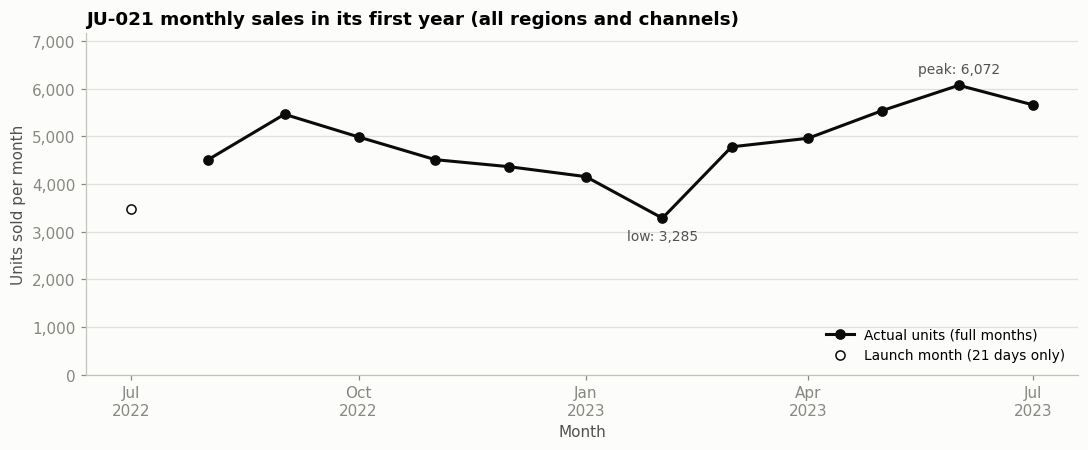

,2022-08,2022-09,2022-10,2022-11,2022-12,2023-01,2023-02,2023-03,2023-04,2023-05,2023-06,2023-07
units,4510.0,5464.0,4988.0,4512.0,4364.0,4156.0,3285.0,4781.0,4961.0,5541.0,6072.0,5661.0
change vs previous month (%),NaN,21.2,-8.7,-9.5,-3.3,-4.8,-21.0,45.5,3.8,11.7,9.6,-6.8
units per day,145.5,182.1,160.9,150.4,140.8,134.1,117.3,154.2,165.4,178.7,202.4,182.6


In [10]:
fig, ax = plt.subplots(figsize=(10, 4.2))
ax.plot(month_ts(frame_fy.index), total_fy.values, color=PALETTE["actual"], marker="o", label="Actual units (full months)")
ax.plot(month_ts([LAUNCH_MONTH]), [launch_month_units], marker="o", markerfacecolor="white",
        color=PALETTE["actual"], linestyle="none", label="Launch month (21 days only)")
peak = total_fy.idxmax(); low = total_fy.idxmin()
for month, va, text in [(peak, "bottom", "peak"), (low, "top", "low")]:
    ax.annotate(f"{text}: {int(total_fy[month]):,}", (month_ts([month])[0], total_fy[month]),
                textcoords="offset points", xytext=(0, 8 if va == "bottom" else -14), ha="center",
                fontsize=9, color=PALETTE["ink2"])
style_axes(ax, "JU-021 monthly sales in its first year (all regions and channels)")
ax.set_ylim(0, total_fy.max() * 1.18)
ax.legend(loc="lower right")
plt.tight_layout(); plt.show()

fy_stats = pd.DataFrame({"units": total_fy.astype(int),
                         "change vs previous month (%)": (total_fy.pct_change() * 100).round(1),
                         "units per day": (total_fy / [p.days_in_month for p in total_fy.index]).round(1)})
display(fy_stats.T)

**Reading.**
* **The first year has a launch-then-season shape.** Sales jumped from launch to a first high in September 2022 (5,464 units). They then eased through autumn and winter to a low in February 2023 (3,285), and climbed steeply through spring to the first-year **peak in June 2023 (6,072)**.
* **Part of February's dip is calendar.** On a units-per-day basis February is less extreme, which is why the ML models get a `days_in_month` feature.
* **Trend and seasonality are tangled together.** From one year of data it is impossible to tell how much of the winter dip is *seasonal* (juice sells less in winter) and how much is the *launch hype fading*. Each calendar month has been observed only once. This is the central limitation of first-year forecasting, and it runs through every result below.

### Regions and channels

Small multiples with one panel per region and per channel, all on the same y-axis, show whether the markets behave alike.

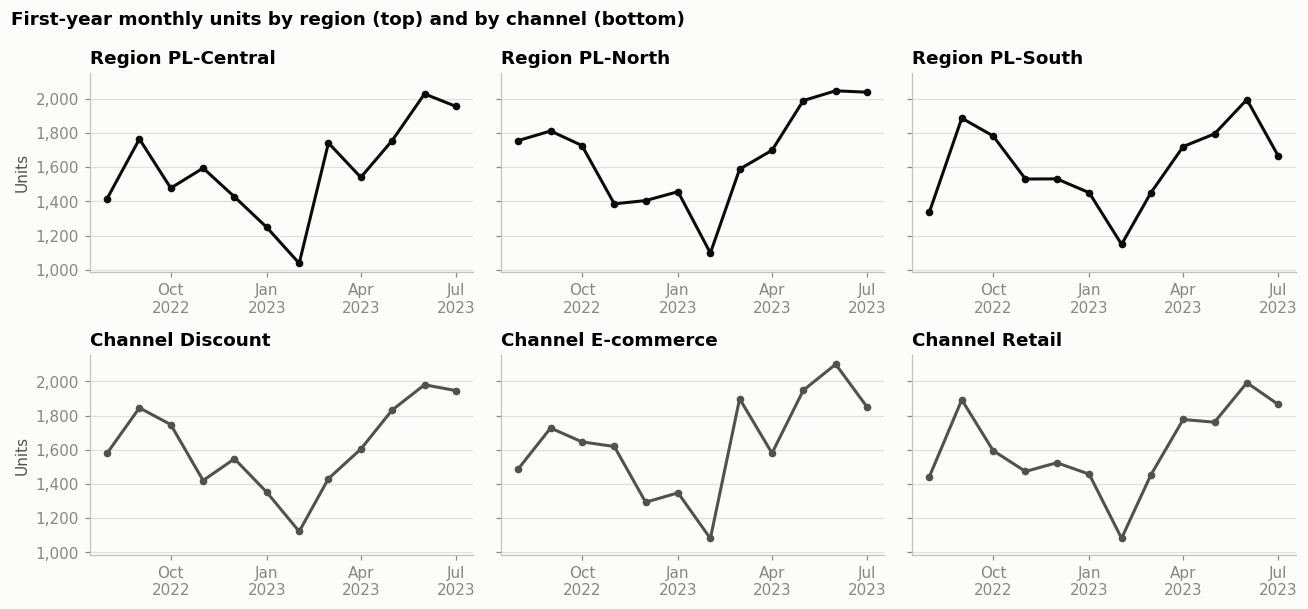

,region share of first-year units (%)
PL-Central,32.6
PL-North,34.3
PL-South,33.1


,channel share of first-year units (%)
Discount,33.3
E-commerce,33.6
Retail,33.1


In [11]:
fig, axes = plt.subplots(2, 3, figsize=(12, 5.6), sharey=True)
for col, region in enumerate(REGIONS):
    s = frame_fy[level_columns(f"region:{region}")].sum(axis=1)
    axes[0, col].plot(month_ts(s.index), s.values, color=PALETTE["actual"], marker="o", markersize=4)
    style_axes(axes[0, col], f"Region {region}", ylabel="Units" if col == 0 else "", xlabel="")
for col, channel in enumerate(CHANNELS):
    s = frame_fy[level_columns(f"channel:{channel}")].sum(axis=1)
    axes[1, col].plot(month_ts(s.index), s.values, color=PALETTE["ink2"], marker="o", markersize=4)
    style_axes(axes[1, col], f"Channel {channel}", ylabel="Units" if col == 0 else "", xlabel="")
fig.suptitle("First-year monthly units by region (top) and by channel (bottom)", x=0.01, ha="left", fontweight="bold")
plt.tight_layout(); plt.show()

shares = pd.DataFrame({
    "region share of first-year units (%)": {r: 100 * frame_fy[level_columns(f"region:{r}")].values.sum() / total_fy.sum() for r in REGIONS},
}).round(1)
chan_shares = pd.DataFrame({
    "channel share of first-year units (%)": {c: 100 * frame_fy[level_columns(f"channel:{c}")].values.sum() / total_fy.sum() for c in CHANNELS},
}).round(1)
display(shares, chan_shares)

**Reading.** All three regions and all three channels follow the same seasonal shape, each with roughly a third of volume. That has two consequences:
1. **Pooling the 9 series is justified.** It lets the ML models learn one common pattern from 9× more rows.
2. **The forecast can be allocated by recent mix.** A total forecast can be split into region × channel production and distribution targets by each series' recent share.

## 6. Feature engineering: lag features and seasonal indicators (Task 1)

### Engine code: features and machine-learning models

The ML models cannot read a time series directly. Each month has to become a row of **features** describing what was known *before* that month:

| Feature | Meaning | Available |
|---|---|---|
| `lag_1`, `lag_2` | sales 1 and 2 months earlier | always |
| `lag_3`, `rolling_mean_3` | sales 3 months earlier, and the 3-month average of past sales | with ≥ 12 training months |
| `lag_12` | sales in the same month last year | with ≥ 24 training months |
| `months_since_launch` | product age, which carries the launch ramp-up and lifecycle trend | always |
| `month_sin`, `month_cos`, `is_summer` | **seasonal indicators**: position in the year as a smooth cycle, plus a June–August flag | always |
| `days_in_month` | calendar effect, e.g. February being short | always |
| `region=…`, `channel=…` | which of the 9 series the row belongs to (one-hot) | always |

**Pooling.** One history gives only a handful of rows, so the Random Forest and XGBoost models are trained on **all 9 region × channel series at once**: 63 rows in year one instead of 7. Their predictions are summed back up to the selected level.

**Recursive forecasting.** For months 2 and 3 of a forecast, the lags come from the model's *own* earlier predictions, never from actual test values. This keeps the test honest and matches how the forecast would be used in practice.

**Hyperparameters are fixed, not tuned**, because tuning on 9 months would overfit:
* Random Forest: 200 trees, min 2 samples per leaf.
* XGBoost: 300 shallow (depth-2) boosted trees, learning rate 0.05, one thread for determinism.

**Random Forest uncertainty band.** Each tree's predictions are added up across the selected series, and the percentiles are taken over those per-tree totals. This is a *heuristic* spread, not a calibrated interval. XGBoost has no native predictive interval, so none is shown for it.

In [12]:
def feature_spec(n_train: int) -> dict:
    """Which features are allowed given the number of training months."""
    lags = [1, 2] + ([3] if n_train >= RICH_LAG_MIN_TRAIN else [])
    use_rolling = n_train >= RICH_LAG_MIN_TRAIN
    use_lag12 = n_train >= SEASONAL_MIN_TRAIN
    numeric = ([f"lag_{l}" for l in lags] + (["rolling_mean_3"] if use_rolling else [])
               + (["lag_12"] if use_lag12 else [])
               + ["months_since_launch", "month_sin", "month_cos", "is_summer", "days_in_month"])
    dummies = [f"region={r}" for r in REGIONS] + [f"channel={c}" for c in CHANNELS]
    return {"lags": lags, "rolling": use_rolling, "lag12": use_lag12,
            "numeric": numeric, "columns": numeric + dummies}


def feature_row(history, period, series_key: str, spec: dict, launch) -> dict:
    """Features for one series in one month, using only values observed BEFORE that month."""
    row = {}
    for lag in spec["lags"]:
        row[f"lag_{lag}"] = float(history[-lag]) if len(history) >= lag else np.nan
    if spec["rolling"]:
        row["rolling_mean_3"] = float(np.mean(history[-3:])) if len(history) >= 3 else np.nan
    if spec["lag12"]:
        row["lag_12"] = float(history[-12]) if len(history) >= 12 else np.nan
    month = period.month
    row["months_since_launch"] = float((period - launch).n)
    row["month_sin"] = math.sin(2 * math.pi * month / 12)
    row["month_cos"] = math.cos(2 * math.pi * month / 12)
    row["is_summer"] = 1.0 if month in (6, 7, 8) else 0.0
    row["days_in_month"] = float(period.days_in_month)
    region, channel = series_key.split("|")
    for r in REGIONS:
        row[f"region={r}"] = 1.0 if r == region else 0.0
    for c in CHANNELS:
        row[f"channel={c}"] = 1.0 if c == channel else 0.0
    return row


def build_training_set(frame: pd.DataFrame, spec: dict, launch):
    """Pooled training table: one row per (series, month) whose features are all available."""
    rows, target, keys = [], [], []
    for key in SERIES:
        values = frame[key].to_numpy(dtype=float)
        for t in range(values.size):
            row = feature_row(values[:t], frame.index[t], key, spec, launch)
            if any(np.isnan(row[c]) for c in spec["numeric"]):
                continue
            rows.append(row)
            target.append(values[t])
            keys.append({"series": key, "month": str(frame.index[t])})
    return pd.DataFrame(rows, columns=spec["columns"]), np.asarray(target, dtype=float), keys


def make_ml_model(kind: str):
    if kind == "rf":
        return RandomForestRegressor(n_estimators=200, min_samples_leaf=2,
                                     random_state=RANDOM_STATE, n_jobs=1)
    if kind == "xgb":
        return XGBRegressor(n_estimators=300, max_depth=2, learning_rate=0.05, subsample=1.0,
                            colsample_bytree=1.0, objective="reg:squarederror",
                            random_state=RANDOM_STATE, n_jobs=1)
    raise ValueError(kind)


def fit_ml(kind: str, frame: pd.DataFrame, launch) -> dict:
    spec = feature_spec(len(frame))
    X, y, keys = build_training_set(frame, spec, launch)
    model = make_ml_model(kind)
    model.fit(X, y)
    return {"model": model, "spec": spec, "X": X, "y": y, "keys": keys}


def ml_recursive_forecast(fitted: dict, frame: pd.DataFrame, launch, h: int, with_trees: bool = False):
    """Recursive multi-step forecast for all 9 series. Optionally per-tree predictions (RF)."""
    model, spec = fitted["model"], fitted["spec"]
    history = {k: list(frame[k].to_numpy(dtype=float)) for k in SERIES}
    last = frame.index[-1]
    point = {k: [] for k in SERIES}
    per_tree = []                                     # one (n_trees x 9) array per step
    for step in range(1, h + 1):
        period = last + step
        X = pd.DataFrame([feature_row(history[k], period, k, spec, launch) for k in SERIES],
                         columns=spec["columns"])
        if with_trees:
            # One prediction per tree; the forest's point forecast is their mean.
            trees = np.stack([est.predict(X.to_numpy(dtype=float)) for est in model.estimators_])
            per_tree.append(trees)
            pred = np.maximum(trees.mean(axis=0), 0.0)
        else:
            pred = np.maximum(np.asarray(model.predict(X), dtype=float), 0.0)
        for i, k in enumerate(SERIES):
            point[k].append(float(pred[i]))
            history[k].append(float(pred[i]))
    return point, per_tree


def feature_importance(model, columns) -> list:
    """Normalised importance with the one-hot identifiers grouped into 'region' and 'channel'."""
    raw = np.asarray(model.feature_importances_, dtype=float)
    total = float(raw.sum()) or 1.0
    grouped = {}
    for col, value in zip(columns, raw / total):
        name = "region (one-hot)" if col.startswith("region=") else (
            "channel (one-hot)" if col.startswith("channel=") else col)
        grouped[name] = grouped.get(name, 0.0) + float(value)
    return sorted(({"feature": k, "importance": v} for k, v in grouped.items()),
                  key=lambda d: -d["importance"])

### The feature table the ML models train on

The training window is the first 9 months (see §8), and with 9 training months the feature rules give the following feature set. Here are the first rows of the pooled training table. Every row is one series in one month, with only *earlier* months used in its features.

In [13]:
N_TRAIN_DEFAULT = FIRST_YEAR_MONTHS - DEFAULT_CONFIG["test_size"]
spec9 = feature_spec(N_TRAIN_DEFAULT)
X9, y9, keys9 = build_training_set(frame_fy.iloc[:N_TRAIN_DEFAULT], spec9, LAUNCH_MONTH)
print(f"Feature set with {N_TRAIN_DEFAULT} training months: {spec9['numeric']}")
print(f"Pooled training rows: {len(X9)} (= 9 series x {len(X9) // 9} months with lag_1 and lag_2 available)")
preview = pd.concat([pd.DataFrame(keys9), X9.round(3), pd.Series(y9, name="target_units")], axis=1)
display(preview.head(8))

# Leakage check: lag_1 of each row must equal the previous month's actual value of that series.
check = pd.DataFrame(keys9).assign(lag_1=X9["lag_1"].values)
for k, row in check.iterrows():
    prev = (pd.Period(row["month"], freq="M") - 1)
    assert row["lag_1"] == frame_fy.loc[prev, row["series"]], "lag_1 must come from the previous month"
print("Leakage check passed: every lag_1 equals the actual value of the previous month.")

Feature set with 9 training months: ['lag_1', 'lag_2', 'months_since_launch', 'month_sin', 'month_cos', 'is_summer', 'days_in_month']
Pooled training rows: 63 (= 9 series x 7 months with lag_1 and lag_2 available)


,series,month,lag_1,lag_2,months_since_launch,month_sin,month_cos,is_summer,days_in_month,region=PL-Central,region=PL-North,region=PL-South,channel=Discount,channel=E-commerce,channel=Retail,target_units
0,PL-Central|Discount,2022-10,651.0,465.0,3.0,-0.866,0.500,0.0,31.0,1.0,0.0,0.0,1.0,0.0,0.0,512.0
1,PL-Central|Discount,2022-11,512.0,651.0,4.0,-0.500,0.866,0.0,30.0,1.0,0.0,0.0,1.0,0.0,0.0,475.0
2,PL-Central|Discount,2022-12,475.0,512.0,5.0,-0.000,1.000,0.0,31.0,1.0,0.0,0.0,1.0,0.0,0.0,512.0
3,PL-Central|Discount,2023-01,512.0,475.0,6.0,0.500,0.866,0.0,31.0,1.0,0.0,0.0,1.0,0.0,0.0,351.0
4,PL-Central|Discount,2023-02,351.0,512.0,7.0,0.866,0.500,0.0,28.0,1.0,0.0,0.0,1.0,0.0,0.0,383.0
5,PL-Central|Discount,2023-03,383.0,351.0,8.0,1.000,0.000,0.0,31.0,1.0,0.0,0.0,1.0,0.0,0.0,499.0
6,PL-Central|Discount,2023-04,499.0,383.0,9.0,0.866,-0.500,0.0,30.0,1.0,0.0,0.0,1.0,0.0,0.0,492.0
7,PL-Central|E-commerce,2022-10,607.0,516.0,3.0,-0.866,0.500,0.0,31.0,1.0,0.0,0.0,0.0,1.0,0.0,419.0


Leakage check passed: every lag_1 equals the actual value of the previous month.


### How informative are the lags and seasonal indicators?

* **Left:** each series-month against its own previous month (`lag_1`), pooled over the 9 series. Points close to the diagonal mean "next month looks like this month".
* **Right:** the autocorrelation of total first-year sales. Bars outside the dashed band (±1.96/√n) are statistically distinguishable from zero.

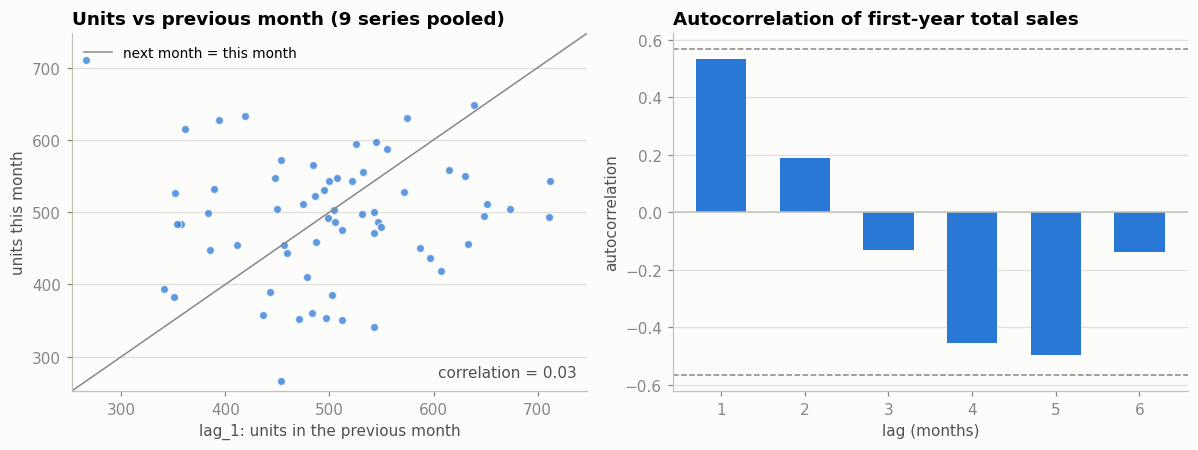

Series level: correlation(units, lag_1) = 0.03
Total level:  ACF lags 1-6 = [ 0.53  0.19 -0.13 -0.46 -0.5  -0.14] | significance band +/-0.57


In [14]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.2))
ax1.scatter(X9["lag_1"], y9, s=28, color=PALETTE["naive"], alpha=0.75, edgecolor=PALETTE["surface"], linewidth=0.8)
lims = [min(X9["lag_1"].min(), y9.min()) * 0.95, max(X9["lag_1"].max(), y9.max()) * 1.05]
ax1.plot(lims, lims, color=PALETTE["muted"], lw=1, label="next month = this month")
ax1.set_xlim(lims); ax1.set_ylim(lims)
ax1.set_title("Units vs previous month (9 series pooled)")
ax1.set_xlabel("lag_1: units in the previous month"); ax1.set_ylabel("units this month")
ax1.legend(loc="upper left")
corr1 = np.corrcoef(X9["lag_1"], y9)[0, 1]
ax1.text(0.98, 0.04, f"correlation = {corr1:.2f}", transform=ax1.transAxes, ha="right", color=PALETTE["ink2"])

nlags = 6
acf_fy = acf(total_fy.values, nlags=nlags, fft=False)
bound = 1.96 / np.sqrt(len(total_fy))
ax2.bar(range(1, nlags + 1), acf_fy[1:], color=PALETTE["naive"], width=0.6)
ax2.axhline(bound, color=PALETTE["muted"], ls="--", lw=1); ax2.axhline(-bound, color=PALETTE["muted"], ls="--", lw=1)
ax2.axhline(0, color=PALETTE["axis"], lw=1)
ax2.set_title("Autocorrelation of first-year total sales"); ax2.set_xlabel("lag (months)"); ax2.set_ylabel("autocorrelation")
plt.tight_layout(); plt.show()
print(f"Series level: correlation(units, lag_1) = {corr1:.2f}")
print("Total level:  ACF lags 1-6 =", np.round(acf_fy[1:], 2), f"| significance band +/-{bound:.2f}")
assert abs(corr1) < 0.1 and abs(acf_fy[1]) < bound      # keeps the reading below true

**Reading.** These are two important and slightly surprising findings.

* **At the level of an individual region × channel series, last month tells you almost nothing about this month:** the correlation is about 0.03. Each series sells only a few hundred units a month, and it is dominated by noise: random daily demand, promotions and stockouts. The points scatter widely around the diagonal. For the ML models, the lag features of a single series are therefore weak inputs.
* **The total is smoother, but 12 points prove little.** The total's lag-1 autocorrelation (0.53) is its strongest, but it still sits inside the ±0.57 significance band for 12 observations. The negative values at lags 4–5 reflect the rise-fall-rise shape of the year, not a reliable cycle.
* **Seasonal indicators are a promise, not yet a signal.** `month_sin`, `month_cos` and `is_summer` describe *where in the year* a month falls. With one year each calendar position appears once, so a model cannot tell a seasonal effect from the launch ramp-up. `lag_12`, the most direct seasonal feature, is **impossible** until a second year exists. §13 shows the seasonal features starting to work as data accumulates.

The practical consequence is that, in year one, the most reliable signal is the **recent level of the total**. Detailed series-level patterns are too noisy to learn from 9 months.

## 7. Model selection (Task 2)

The slide lists Naive, ARIMA and ML models (Random Forest, XGBoost). We use **all of them plus Seasonal Naive** and compare them fairly. "Which model performed best and why?" can only be answered from a comparison.

| Model | Family | Why it is in the comparison | What 12 months of data allow |
|---|---|---|---|
| **Naive** | baseline | The benchmark any model must beat. It is strong when the level drifts | Fully usable |
| **Seasonal Naive** | baseline | The simplest test of whether "same month last year" helps | Needs 12 months *before* the test window, so **not evaluable in year 1**; forecastable once 12 months exist |
| **ARIMA** | statistical | Models autocorrelation and drift in one series | Only low orders (p, q ≤ 1) with 9 training points; **no seasonal terms** until 24 months |
| **Random Forest** | machine learning | Learns non-linear effects of lags, age and season, pooled over 9 series | 63 training rows, but noisy (§6); trees cannot extrapolate beyond levels they have seen |
| **XGBoost** | machine learning | Gradient boosting, a different way of combining trees | Same features and pooling; no native uncertainty range |

Every model is scored on the same target (total units), the same chronological test window and the same horizon, with the same metric functions.

The engine code for the statistical models follows. The machine-learning models and their features were defined in §6.

### Engine code: statistical models

* **Naive.** Next month equals the last observed month. Its uncertainty grows with the square root of the horizon, as for a random walk. σ is the root-mean-square of the month-to-month changes (Hyndman & Athanasopoulos, *FPP3* §5.5).
* **Seasonal Naive.** Next month equals the same month last year. It needs at least 12 months of history. Its interval uses the year-over-year changes once at least 3 exist.
* **ARIMA** (statsmodels, exact maximum likelihood):
  * First differencing (d = 1) is fixed, because a launching product's level keeps shifting.
  * The orders p and q (0 or 1), with or without drift, are chosen by **AICc**, which is AIC corrected for small samples.
  * With at least 24 training months, a seasonal difference at lag 12 is added instead of drift.
  * Candidates are compared only within the same differencing, and a candidate is skipped when AICc is undefined (too few observations for its parameters).

Lower bounds of every interval are clipped at 0, because sales cannot be negative.

In [15]:
def _interval(point, se) -> dict:
    point = np.asarray(point, dtype=float)
    se = np.asarray(se, dtype=float)
    return {
        "lo80": np.maximum(point - Z80 * se, 0.0), "hi80": point + Z80 * se,
        "lo95": np.maximum(point - Z95 * se, 0.0), "hi95": point + Z95 * se,
    }


def forecast_naive(y, h: int) -> dict:
    """Naive forecast: repeat the last value; random-walk prediction interval."""
    y = np.asarray(y, dtype=float)
    point = np.repeat(y[-1], h)
    out = {"point": point, "info": {"method": "Last observed month carried forward."}}
    resid = np.diff(y)
    if resid.size >= 1:
        sigma = float(np.sqrt(np.mean(resid ** 2)))
        out.update(_interval(point, sigma * np.sqrt(np.arange(1, h + 1))))
        out["info"]["residual_sigma"] = sigma
    return out


def forecast_snaive(y, h: int, m: int = SEASON_PERIOD):
    """Seasonal naive forecast: same month one year earlier. None if fewer than m months."""
    y = np.asarray(y, dtype=float)
    n = y.size
    if n < m:
        return None
    point = np.array([y[n - m + (i % m)] for i in range(h)])
    out = {"point": point, "info": {"method": "Same calendar month one year earlier."}}
    resid = y[m:] - y[:-m]
    if resid.size >= 3:
        sigma = float(np.sqrt(np.mean(resid ** 2)))
        k = np.arange(h) // m
        out.update(_interval(point, sigma * np.sqrt(k + 1)))
        out["info"]["residual_sigma"] = sigma
    return out


def arima_label(order, seasonal_order, trend) -> str:
    text = f"ARIMA({order[0]},{order[1]},{order[2]})"
    if seasonal_order and seasonal_order[3]:
        text += f"({seasonal_order[0]},{seasonal_order[1]},{seasonal_order[2]})[{seasonal_order[3]}]"
    if trend == "t":
        text += " with drift"
    elif trend == "c":
        text += " with constant"
    return text


def _arima_candidates(n_obs: int, order_override=None) -> list:
    seasonal = n_obs >= SEASONAL_MIN_TRAIN
    sorder = (0, 1, 0, SEASON_PERIOD) if seasonal else (0, 0, 0, 0)
    if order_override is not None:
        p, d, q = (int(v) for v in order_override)
        trend = "n" if (d + sorder[1]) > 0 else "c"
        return [((p, d, q), sorder, trend)]
    candidates = []
    for p in (0, 1):
        for q in (0, 1):
            for trend in (("n",) if seasonal else ("n", "t")):
                candidates.append(((p, 1, q), sorder, trend))
    return candidates


def forecast_arima(y, h: int, order_override=None):
    """Small-grid ARIMA chosen by AICc; returns point forecast and model-based intervals."""
    y = np.asarray(y, dtype=float)
    n = y.size
    best, tried = None, []
    for order, sorder, trend in _arima_candidates(n, order_override):
        k = order[0] + order[2] + (1 if trend in ("c", "t") else 0) + 1      # + noise variance
        n_eff = n - order[1] - sorder[1] * sorder[3]
        label = arima_label(order, sorder, trend)
        if n_eff - k - 1 <= 0:
            tried.append({"model": label, "aicc": None, "status": "skipped: too few observations"})
            continue
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter("always")
            try:
                res = ARIMA(y, order=order, seasonal_order=sorder, trend=trend).fit()
            except Exception as exc:          # numerical failure on tiny samples
                tried.append({"model": label, "aicc": None, "status": f"failed: {type(exc).__name__}"})
                continue
        aicc = float(res.aicc)
        tried.append({"model": label, "aicc": aicc if np.isfinite(aicc) else None,
                      "status": "fitted", "warnings": len(caught)})
        if np.isfinite(aicc) and (best is None or aicc < best[0] - 1e-9):
            best = (aicc, order, sorder, trend, res, len(caught))
    if best is None:
        return None
    aicc, order, sorder, trend, res, n_warn = best
    fc = res.get_forecast(h)
    point = np.asarray(fc.predicted_mean, dtype=float)
    ci80 = np.asarray(fc.conf_int(alpha=0.20), dtype=float)
    ci95 = np.asarray(fc.conf_int(alpha=0.05), dtype=float)
    return {
        "point": point,
        "lo80": np.maximum(ci80[:, 0], 0.0), "hi80": ci80[:, 1],
        "lo95": np.maximum(ci95[:, 0], 0.0), "hi95": ci95[:, 1],
        "info": {"label": arima_label(order, sorder, trend), "order": list(order),
                 "seasonal_order": list(sorder), "trend": trend, "aicc": aicc,
                 "convergence_warnings": n_warn, "candidates": tried,
                 "method": "Lowest AICc on a small (p,1,q) grid."},
    }

## 8. Train/test split (Task 3)

**The split has to be chronological.** A random split would put future months into training and let the models "see" the period they are tested on, which inflates accuracy. Forecasting is always about predicting months *after* the data you have.

**Why 9 training and 3 test months:**
* The test window of **3 months** matches the **3-month forecast horizon** on the slide, so test errors measure exactly the kind of forecast the company will use.
* **9 training months** is the most we can keep while still holding out 3. It leaves 7 usable rows per series for the lag-2 features (63 pooled rows) and 8 differenced points for ARIMA. A longer test window would starve the models; a shorter one would make the error estimate rest on one or two months.
* Every model is evaluated on these same 3 months. Afterwards every model is **refit on all 12 months** before the real forecast (§11).

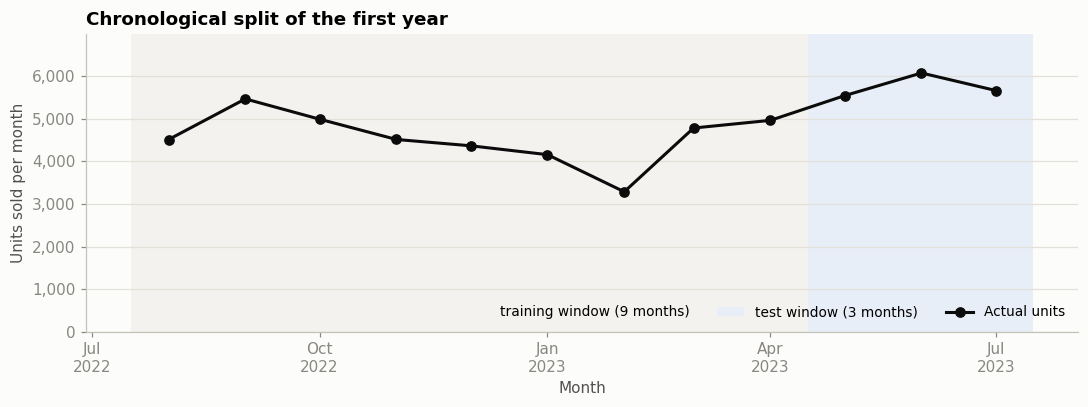

Train: 2022-08 to 2023-04 (9 months) | Test: 2023-05 to 2023-07 (3 months)


In [16]:
split_train = frame_fy.index[:N_TRAIN_DEFAULT]
split_test = frame_fy.index[N_TRAIN_DEFAULT:]
fig, ax = plt.subplots(figsize=(10, 3.8))
shade(ax, split_train, PALETTE["train"], "training window (9 months)")
shade(ax, split_test, PALETTE["test"], "test window (3 months)")
ax.plot(month_ts(frame_fy.index), total_fy.values, color=PALETTE["actual"], marker="o", label="Actual units")
style_axes(ax, "Chronological split of the first year")
ax.set_ylim(0, total_fy.max() * 1.15)
ax.legend(loc="lower right", ncol=3)
plt.tight_layout(); plt.show()
print(f"Train: {split_train[0]} to {split_train[-1]} ({len(split_train)} months) | "
      f"Test: {split_test[0]} to {split_test[-1]} ({len(split_test)} months)")

**Reading.** The test window, May–July 2023, is the product's **first full summer**: a steep rise to the first-year peak. A model trained on August–April has never seen a summer except the launch month's tail. The test is therefore demanding, and it directly measures the slide's question of how well the models capture seasonality.

## 9. Accuracy metrics: MAPE and WAPE (Task 5)

### Engine code: accuracy metrics

The slide asks for **MAPE** and **WAPE**. Both are written out explicitly so the definitions can be checked by hand. *A* is the actual value and *F* the forecast for each of the *n* test months.

* **MAPE**: the mean of |A − F| / |A|, × 100. Every month counts equally, however small its volume. It is **undefined when A = 0**: such months are excluded and the number excluded is reported. If an actual is close to zero (below 5% of the average), the result gets a warning, because one tiny denominator can inflate MAPE.
* **WAPE**: Σ|A − F| / Σ|A|, × 100. Total error is divided by total volume, so busy months count more. It is undefined only if every actual is zero. WAPE is the **primary decision metric** here because production is planned in units.
* **Bias** is an extra diagnostic: Σ(F − A) / Σ|A| × 100. A negative value means under-forecasting, a risk of stockouts. A positive value means over-forecasting, a risk of surplus stock.

In [17]:
def mape(actual, forecast) -> dict:
    """Mean Absolute Percentage Error (%), excluding months whose actual is exactly zero."""
    a = np.asarray(actual, dtype=float)
    f = np.asarray(forecast, dtype=float)
    used = a != 0
    out = {"value": None, "n_used": int(used.sum()), "n_excluded_zero": int((~used).sum()),
           "near_zero_warning": False, "reason": None}
    if not used.any():
        out["reason"] = "MAPE is undefined because every actual value is zero."
        return out
    ape = np.abs(a[used] - f[used]) / np.abs(a[used])
    out["value"] = float(100.0 * ape.mean())
    scale = float(np.mean(np.abs(a)))
    out["near_zero_warning"] = bool(np.any(np.abs(a[used]) < NEAR_ZERO_SHARE * scale))
    return out


def wape(actual, forecast) -> dict:
    """Weighted Absolute Percentage Error (%) = total absolute error / total actual volume."""
    a = np.asarray(actual, dtype=float)
    f = np.asarray(forecast, dtype=float)
    denom = float(np.sum(np.abs(a)))
    if denom == 0:
        return {"value": None, "reason": "WAPE is undefined because total actual volume is zero."}
    return {"value": float(100.0 * np.sum(np.abs(a - f)) / denom), "reason": None}


def bias(actual, forecast) -> dict:
    """Signed bias (%) = total (forecast - actual) / total actual volume. Negative = under-forecast."""
    a = np.asarray(actual, dtype=float)
    f = np.asarray(forecast, dtype=float)
    denom = float(np.sum(np.abs(a)))
    if denom == 0:
        return {"value": None, "reason": "Bias is undefined because total actual volume is zero."}
    return {"value": float(100.0 * np.sum(f - a) / denom), "reason": None}


def evaluate_forecast(actual, forecast, months) -> dict:
    """All accuracy figures for one model on one test window, plus the per-month working."""
    a = np.asarray(actual, dtype=float)
    f = np.asarray(forecast, dtype=float)
    per_month = []
    for m, ai, fi in zip(months, a, f):
        per_month.append({
            "month": str(m), "actual": float(ai), "forecast": float(fi), "error": float(fi - ai),
            "abs_error": float(abs(fi - ai)),
            "abs_pct_error": None if ai == 0 else float(100.0 * abs(fi - ai) / abs(ai)),
        })
    return {"mape": mape(a, f), "wape": wape(a, f), "bias": bias(a, f),
            "abs_error_units": float(np.sum(np.abs(a - f))), "per_month": per_month}

### Hand-calculation cross-check

To prove the metric code is right, we calculate MAPE and WAPE for the **Naive** forecast on the test window by hand, step by step, and assert that the functions give the same answer. The Naive forecast for every test month is simply April 2023, the last training month.

In [18]:
actual_test = total_fy.loc[split_test].to_numpy(dtype=float)
naive_value = total_fy.loc[split_train[-1]]
naive_test = np.repeat(naive_value, len(actual_test))

hand = pd.DataFrame({"month": [str(m) for m in split_test], "A (actual)": actual_test.astype(int),
                     "F (naive)": naive_test.astype(int)})
hand["|A - F|"] = (hand["A (actual)"] - hand["F (naive)"]).abs()
hand["|A - F| / A (%)"] = (100 * hand["|A - F|"] / hand["A (actual)"]).round(2)
display(hand)

mape_by_hand = hand["|A - F| / A (%)"].mean()
wape_by_hand = 100 * hand["|A - F|"].sum() / hand["A (actual)"].sum()
print(f"MAPE by hand = mean of the % column        = {mape_by_hand:.2f}%")
print(f"WAPE by hand = {hand['|A - F|'].sum():,} / {hand['A (actual)'].sum():,} = {wape_by_hand:.2f}%")
print(f"MAPE function = {mape(actual_test, naive_test)['value']:.2f}% | WAPE function = {wape(actual_test, naive_test)['value']:.2f}%")

assert abs(mape(actual_test, naive_test)["value"] - 13.71) < 0.005
assert abs(wape(actual_test, naive_test)["value"] - 13.84) < 0.005
print("Hand calculation and functions agree.")

,month,A (actual),F (naive),|A - F|,|A - F| / A (%)
0,2023-05,5541,4961,580,10.47
1,2023-06,6072,4961,1111,18.30
2,2023-07,5661,4961,700,12.37


MAPE by hand = mean of the % column        = 13.71%
WAPE by hand = 2,391 / 17,274 = 13.84%
MAPE function = 13.71% | WAPE function = 13.84%
Hand calculation and functions agree.


The functions match the hand calculation: **MAPE 13.71%** and **WAPE 13.84%**.

The two differ slightly because MAPE weights the three months equally, while WAPE weights them by volume. June, the biggest month, had the biggest error, so WAPE is a little higher.

**Edge cases.** These are the situations that break naive MAPE implementations, and they must be handled correctly because users can type in their own months in the dashboard.

In [19]:
cases = {
    "one actual is zero": ([0, 100, 200], [10, 110, 190]),
    "near-zero actual": ([2, 100, 200], [10, 110, 190]),
    "all actuals zero": ([0, 0, 0], [5, 5, 5]),
    "perfect forecast": ([100, 200, 300], [100, 200, 300]),
}
rows = []
for name, (a, f) in cases.items():
    m, w, b = mape(a, f), wape(a, f), bias(a, f)
    rows.append({"case": name, "MAPE (%)": None if m["value"] is None else round(m["value"], 2),
                 "months excluded": m["n_excluded_zero"], "near-zero warning": m["near_zero_warning"],
                 "WAPE (%)": None if w["value"] is None else round(w["value"], 2),
                 "bias (%)": None if b["value"] is None else round(b["value"], 2),
                 "note": m["reason"] or w["reason"] or ""})
display(pd.DataFrame(rows))
assert mape([0, 100, 200], [10, 110, 190])["n_excluded_zero"] == 1
assert mape([0, 0, 0], [5, 5, 5])["value"] is None and wape([0, 0, 0], [5, 5, 5])["value"] is None

,case,MAPE (%),months excluded,near-zero warning,WAPE (%),bias (%),note
0,one actual is zero,7.50,1,False,10.00,3.33,
1,near-zero actual,138.33,0,True,9.27,2.65,
2,all actuals zero,NaN,3,False,NaN,NaN,MAPE is undefined because every actual value i...
3,perfect forecast,0.00,0,False,0.00,0.00,


**Reading.**
* **A zero actual is skipped by MAPE and reported as excluded.** Dividing by zero would otherwise crash it or give infinity. WAPE is unaffected, since it divides by the total.
* **A near-zero actual triggers a warning.** An actual of 2 units makes MAPE explode (its error is 400% of 2), while WAPE stays sensible. This is why WAPE is the better metric for production decisions.
* **If every actual is zero, both metrics are undefined.** They are reported as *n/a with a reason* rather than as a misleading number.

## 10. Train, test and compare all models (Tasks 3, 5 and 6)

### Engine code: running a complete scenario

`run_scenario` is the single entry point the notebook and the dashboard share. Given the data available *now* and a configuration (level, test-window length, horizon), it:

1. splits the months **chronologically** into a training window and a test window (Task 3);
2. fits every model on the training window only and scores its test-window forecast with the metrics above (Task 5);
3. **refits every model on all available months** and forecasts the next *h* months with uncertainty ranges (Task 4);
4. ranks the models by WAPE. Models within 0.05 points tie, and models that produce identical forecasts are flagged (in year one, ARIMA's chosen random walk is exactly the Naive forecast);
5. adds the context the interpretation needs: trend and seasonality summaries, regional and channel mix, a region × channel **distribution plan** for the best model, operational signals (stockouts, promotions), and scores for earlier forecasts whose actuals have since arrived.

Models that cannot be evaluated are reported as "not evaluated", with the reason. For example, Seasonal Naive needs 12 training months. They never silently get a score.

In [20]:
def round_half_up(value, ndigits: int = 0):
    """Round half away from zero (the same rule the dashboard uses); None stays None."""
    if value is None:
        return None
    q = Decimal(1).scaleb(-ndigits)
    return float(Decimal(repr(float(value))).quantize(q, rounding=ROUND_HALF_UP))


def normalize_config(config) -> dict:
    cfg = dict(DEFAULT_CONFIG)
    cfg.update({k: v for k, v in (config or {}).items() if v is not None or k == "arima_order"})
    cfg["test_size"] = int(cfg["test_size"])
    cfg["horizon"] = int(cfg["horizon"])
    if not 1 <= cfg["test_size"] <= MAX_TEST_MONTHS:
        raise ValueError(f"test_size must be between 1 and {MAX_TEST_MONTHS}.")
    if not 1 <= cfg["horizon"] <= MAX_HORIZON:
        raise ValueError(f"horizon must be between 1 and {MAX_HORIZON}.")
    level_columns(cfg["level"])                          # validates the level
    if cfg["arima_order"] is not None:
        p, d, q = (int(v) for v in cfg["arima_order"])
        if not (0 <= p <= 2 and 0 <= d <= 1 and 0 <= q <= 2):
            raise ValueError("ARIMA order override must have p, q in 0..2 and d in 0..1.")
        cfg["arima_order"] = [p, d, q]
    cfg["tracking_log"] = list(cfg.get("tracking_log") or [])
    return cfg


def _model_entry(key: str) -> dict:
    return {"key": key, "label": MODEL_LABELS[key], "family": MODEL_FAMILY[key],
            "evaluated": False, "not_evaluated_reason": None, "test": None,
            "forecast": None, "forecast_reason": None, "info": {}}


def _forecast_block(months, fc: dict) -> dict:
    block = {"months": [str(m) for m in months], "point": [float(v) for v in fc["point"]]}
    for b in ("lo80", "hi80", "lo95", "hi95"):
        block[b] = [float(v) for v in fc[b]] if fc.get(b) is not None else None
    return block


def _rank_models(models: dict) -> list:
    scored = [(m["test"]["metrics"]["wape"]["value"], MODEL_ORDER.index(k), k)
              for k, m in models.items()
              if m["evaluated"] and m["test"]["metrics"]["wape"]["value"] is not None]
    scored.sort()
    ranking, leader_wape, leader_rank = [], None, 0
    for position, (w, _, key) in enumerate(scored, start=1):
        if leader_wape is None or w - leader_wape > TIE_TOLERANCE_PP:
            leader_wape, leader_rank = w, position
        m = models[key]["test"]["metrics"]
        ranking.append({"rank": leader_rank, "model": key, "label": MODEL_LABELS[key],
                        "wape_pct": w, "mape_pct": m["mape"]["value"], "bias_pct": m["bias"]["value"]})
    return ranking


def _last_mix(frame: pd.DataFrame, cols: list, months: int = 3) -> dict:
    recent = frame[cols].iloc[-months:].sum()
    total = float(recent.sum())
    return {k: (float(recent[k]) / total if total else 1.0 / len(cols)) for k in cols}


def _ops_array(panel: dict, field: str, key: str, n: int):
    ops = panel.get("ops") or {}
    values = (ops.get(field) or {}).get(key)
    if values is None:
        return [None] * n
    return [None if v is None else float(v) for v in list(values)[:n]] + [None] * max(0, n - len(values))


def operations_summary(panel: dict, frame: pd.DataFrame, cols: list) -> dict:
    """Stockouts (lost sales) in the last 3 months and the promotion uplift, if counts exist."""
    n = len(frame)
    last3 = range(max(0, n - 3), n)
    stockout_rows, lost, have_stock = 0.0, 0.0, False
    promo_units = promo_rows = base_units = base_rows = 0.0
    have_promo = False
    for key in cols:
        units = frame[key].to_numpy(dtype=float)
        rows = _ops_array(panel, "rows", key, n)
        so = _ops_array(panel, "stockout_rows", key, n)
        pr = _ops_array(panel, "promo_rows", key, n)
        pu = _ops_array(panel, "promo_units", key, n)
        for t in range(n):
            if None in (rows[t], so[t]):
                continue
            in_stock = rows[t] - so[t]
            if t in last3:
                have_stock = True
                stockout_rows += so[t]
                if in_stock > 0:
                    lost += so[t] * units[t] / in_stock
            if None not in (pr[t], pu[t]):
                have_promo = True
                promo_units += pu[t]
                promo_rows += pr[t]
                base_units += units[t] - pu[t]
                base_rows += rows[t] - pr[t]
    uplift = None
    if have_promo and promo_rows > 0 and base_rows > 0 and base_units > 0:
        uplift = (promo_units / promo_rows) / (base_units / base_rows)
    return {
        "stockout_rows_last3": stockout_rows if have_stock else None,
        "est_lost_units_last3": lost if have_stock else None,
        "promo_uplift_ratio": uplift,
        "promo_share_pct": (100.0 * promo_rows / (promo_rows + base_rows)) if have_promo and (promo_rows + base_rows) else None,
        "method": "Lost units = stockout rows x average units per in-stock row of the same series-month.",
    }


def trend_summary(y: np.ndarray, months) -> dict:
    n = y.size
    out = {"latest_month": str(months[-1]), "latest_units": float(y[-1]),
           "mom_change_pct": None, "last3_avg_units": float(np.mean(y[-3:])),
           "prev3_avg_units": None, "last3_vs_prev3_pct": None,
           "peak_month": str(months[int(np.argmax(y))]), "peak_units": float(np.max(y)),
           "low_month": str(months[int(np.argmin(y))]), "low_units": float(np.min(y)),
           "yoy_latest_pct": None, "first3_avg_units": float(np.mean(y[:3])),
           "growth_vs_first3_pct": None}
    if n >= 2 and y[-2]:
        out["mom_change_pct"] = 100.0 * (y[-1] / y[-2] - 1.0)
    if n >= 6:
        prev3 = float(np.mean(y[-6:-3]))
        out["prev3_avg_units"] = prev3
        out["last3_vs_prev3_pct"] = 100.0 * (out["last3_avg_units"] / prev3 - 1.0) if prev3 else None
    if n >= 13 and y[-13]:
        out["yoy_latest_pct"] = 100.0 * (y[-1] / y[-13] - 1.0)
    if out["first3_avg_units"]:
        out["growth_vs_first3_pct"] = 100.0 * (out["last3_avg_units"] / out["first3_avg_units"] - 1.0)
    return out


def seasonality_summary(y: np.ndarray, months) -> dict:
    cal = np.array([m.month for m in months])
    summer = y[np.isin(cal, (6, 7, 8))]
    winter = y[np.isin(cal, (12, 1, 2))]
    counts = pd.Series(cal).value_counts()
    out = {
        "months_of_data": int(y.size),
        "identifiable": bool(y.size >= SEASONAL_MIN_TRAIN),
        "calendar_months_seen_twice": int((counts >= 2).sum()),
        "summer_avg_units": float(summer.mean()) if summer.size else None,
        "winter_avg_units": float(winter.mean()) if winter.size else None,
        "summer_vs_winter_pct": None,
        "profile": [{"calendar_month": int(m.month), "year": int(m.year), "units": float(v)}
                    for m, v in zip(months, y)],
    }
    if summer.size and winter.size and winter.mean():
        out["summer_vs_winter_pct"] = 100.0 * (summer.mean() / winter.mean() - 1.0)
    return out


def mix_summary(frame: pd.DataFrame, dim: str) -> list:
    names = REGIONS if dim == "region" else CHANNELS
    pos = 0 if dim == "region" else 1
    total_last3 = float(frame.iloc[-3:].to_numpy().sum())
    out = []
    for name in names:
        cols = [s for s in SERIES if s.split("|")[pos] == name]
        series = frame[cols].sum(axis=1).to_numpy(dtype=float)
        last3 = float(series[-3:].sum())
        prev3 = float(series[-6:-3].sum()) if series.size >= 6 else None
        out.append({dim: name, "units_last3": last3,
                    "share_last3_pct": 100.0 * last3 / total_last3 if total_last3 else None,
                    "change_last3_vs_prev3_pct": (100.0 * (last3 / prev3 - 1.0)) if prev3 else None})
    return out


def diagnostics_summary(y: np.ndarray, months) -> dict:
    n = y.size
    nlags = int(min(12, n - 2))
    acf_values = [float(v) for v in acf(y, nlags=nlags, fft=False)] if nlags >= 1 else [1.0]
    return {
        "acf": acf_values, "acf_bound": float(1.96 / math.sqrt(n)),
        "lag_pairs": [{"month": str(months[t]), "y": float(y[t]), "lag_1": float(y[t - 1]),
                       "lag_2": float(y[t - 2]) if t >= 2 else None} for t in range(1, n)],
    }


def forecast_log_entries(result: dict) -> list:
    """Forecasts made now, to be scored later when their actuals arrive (forecast tracking)."""
    entries = []
    origin = result["meta"]["data_through"]
    for key in MODEL_ORDER:
        fc = result["models"][key]["forecast"]
        if not fc:
            continue
        for i, month in enumerate(fc["months"]):
            entry = {"origin": origin, "level": result["config"]["level"], "model": key,
                     "target": month, "step": i + 1, "forecast": fc["point"][i]}
            for b in ("lo80", "hi80", "lo95", "hi95"):
                entry[b] = fc[b][i] if fc[b] is not None else None
            entries.append(entry)
    return entries


def score_tracking(log: list, level_series: pd.Series, level: str) -> dict:
    """Score earlier forecasts (same level) against actuals that have arrived since."""
    actual = {str(p): float(v) for p, v in level_series.items()}
    latest = {}
    for e in log:                                      # keep the latest copy of each forecast
        if e.get("level") == level:
            latest[(e["origin"], e["model"], e["target"])] = e
    scored = [dict(e, actual=actual[e["target"]]) for e in latest.values() if e["target"] in actual]
    by_model = []
    for key in MODEL_ORDER:
        rows = [e for e in scored if e["model"] == key]
        if not rows:
            continue
        a = np.array([e["actual"] for e in rows])
        f = np.array([e["forecast"] for e in rows])
        with_80 = [e for e in rows if e.get("lo80") is not None]
        with_95 = [e for e in rows if e.get("lo95") is not None]
        by_model.append({
            "model": key, "label": MODEL_LABELS[key], "n_points": len(rows),
            "wape_pct": wape(a, f)["value"], "mape_pct": mape(a, f)["value"],
            "bias_pct": bias(a, f)["value"],
            "coverage80_pct": (100.0 * np.mean([e["lo80"] <= e["actual"] <= e["hi80"] for e in with_80])) if with_80 else None,
            "coverage95_pct": (100.0 * np.mean([e["lo95"] <= e["actual"] <= e["hi95"] for e in with_95])) if with_95 else None,
        })
    scored.sort(key=lambda e: (e["target"], e["origin"], MODEL_ORDER.index(e["model"])))
    return {"n_scored": len(scored), "by_model": by_model, "scored": scored}

In [21]:
def run_scenario(panel: dict, config=None) -> dict:
    """Train/test evaluation + refit + forecast for every model, on the data available now."""
    cfg = normalize_config(config)
    frame = panel_frame(panel)
    launch = pd.Period(panel.get("launch_month", "2022-07"), freq="M")
    n = len(frame)
    n_test, h = cfg["test_size"], cfg["horizon"]
    n_train = n - n_test
    if n_train < MIN_TRAIN_MONTHS:
        raise ValueError(f"{n} months leave {n_train} training months; at least {MIN_TRAIN_MONTHS} are needed.")
    cols = level_columns(cfg["level"])
    level_series = frame[cols].sum(axis=1)
    y = level_series.to_numpy(dtype=float)
    months = frame.index
    test_months = months[n_train:]
    future_months = [months[-1] + i for i in range(1, h + 1)]
    actual_test = y[n_train:]
    train_frame = frame.iloc[:n_train]
    models = {k: _model_entry(k) for k in MODEL_ORDER}
    series_forecasts = {}                                 # per-series future forecasts (ML)

    def set_test(key, pred, info=None):
        models[key]["evaluated"] = True
        models[key]["test"] = {"months": [str(m) for m in test_months],
                               "predicted": [float(v) for v in pred],
                               "metrics": evaluate_forecast(actual_test, pred, test_months)}
        if info:
            models[key]["info"]["test_fit"] = info

    # --- Naive -----------------------------------------------------------
    set_test("naive", forecast_naive(y[:n_train], n_test)["point"])
    fut = forecast_naive(y, h)
    models["naive"]["forecast"] = _forecast_block(future_months, fut)
    models["naive"]["info"]["method"] = fut["info"]["method"]

    # --- Seasonal naive --------------------------------------------------
    test_fc = forecast_snaive(y[:n_train], n_test)
    if test_fc is None:
        models["snaive"]["not_evaluated_reason"] = (
            f"Needs at least {SEASON_PERIOD} training months; only {n_train} are available.")
    else:
        set_test("snaive", test_fc["point"])
    fut = forecast_snaive(y, h)
    if fut is None:
        models["snaive"]["forecast_reason"] = f"Needs at least {SEASON_PERIOD} months of history."
    else:
        models["snaive"]["forecast"] = _forecast_block(future_months, fut)
        models["snaive"]["info"]["method"] = fut["info"]["method"]

    # --- ARIMA -----------------------------------------------------------
    test_fc = forecast_arima(y[:n_train], n_test, cfg["arima_order"])
    if test_fc is None:
        models["arima"]["not_evaluated_reason"] = "No ARIMA candidate could be estimated on the training window."
    else:
        set_test("arima", test_fc["point"], {"label": test_fc["info"]["label"]})
    fut = forecast_arima(y, h, cfg["arima_order"])
    if fut is None:
        models["arima"]["forecast_reason"] = "No ARIMA candidate could be estimated."
    else:
        models["arima"]["forecast"] = _forecast_block(future_months, fut)
        models["arima"]["info"].update(fut["info"])

    # --- Random forest & XGBoost (pooled over the 9 series) --------------
    features_table = None
    for key in ("rf", "xgb"):
        fitted_test = fit_ml(key, train_frame, launch)
        pts, _ = ml_recursive_forecast(fitted_test, train_frame, launch, n_test)
        set_test(key, [sum(pts[c][i] for c in cols) for i in range(n_test)],
                 {"training_rows": int(len(fitted_test["y"])), "features": fitted_test["spec"]["columns"]})
        if key == "rf":
            features_table = {"columns": fitted_test["spec"]["columns"],
                              "rows": [dict(k, **{c: float(v) for c, v in row.items()}, target=float(t))
                                       for k, row, t in zip(fitted_test["keys"],
                                                            fitted_test["X"].to_dict(orient="records"),
                                                            fitted_test["y"])]}
        fitted_full = fit_ml(key, frame, launch)
        pts, trees = ml_recursive_forecast(fitted_full, frame, launch, h, with_trees=(key == "rf"))
        series_forecasts[key] = pts
        level_point = [sum(pts[c][i] for c in cols) for i in range(h)]
        fc = {"point": level_point, "lo80": None, "hi80": None, "lo95": None, "hi95": None}
        if key == "rf":
            col_idx = [SERIES.index(c) for c in cols]
            totals = np.stack([step[:, col_idx].sum(axis=1) for step in trees], axis=1)  # trees x h
            fc.update({"lo80": np.percentile(totals, 10, axis=0), "hi80": np.percentile(totals, 90, axis=0),
                       "lo95": np.percentile(totals, 2.5, axis=0), "hi95": np.percentile(totals, 97.5, axis=0)})
        models[key]["forecast"] = _forecast_block(future_months, fc)
        models[key]["info"].update({
            "training_rows": int(len(fitted_full["y"])), "features": fitted_full["spec"]["columns"],
            "importance": feature_importance(fitted_full["model"], fitted_full["spec"]["columns"]),
            "interval": "tree-spread heuristic (10-90 / 2.5-97.5 percentiles)" if key == "rf" else "none",
        })

    # --- Ranking, ties, skill vs naive ----------------------------------
    ranking = _rank_models(models)
    naive_w = models["naive"]["test"]["metrics"]["wape"]["value"]
    for key, m in models.items():
        if not m["evaluated"]:
            continue
        w = m["test"]["metrics"]["wape"]["value"]
        m["test"]["skill_vs_naive_pct"] = (100.0 * (1.0 - w / naive_w)) if (naive_w and w is not None) else None
        m["test"]["identical_to"] = [
            other for other, o in models.items()
            if other != key and o["evaluated"]
            and np.allclose(o["test"]["predicted"], m["test"]["predicted"], rtol=0, atol=1e-6)]
    best_models = [r["model"] for r in ranking if r["rank"] == 1]

    # --- Distribution plan for the best model ---------------------------
    distribution = None
    if ranking:
        best = ranking[0]["model"]
        if best in series_forecasts:
            cells = {c: series_forecasts[best][c] for c in cols}
            method = "Bottom-up: the model forecasts each region x channel series directly."
        else:
            mix = _last_mix(frame, cols)
            level_fc = models[best]["forecast"]["point"]
            cells = {c: [share * v for v in level_fc] for c, share in mix.items()}
            method = "Split of the level forecast by each series' share of the last 3 months."
        distribution = {"model": best, "label": MODEL_LABELS[best], "method": method,
                        "months": [str(m) for m in future_months],
                        "cells": [{"region": c.split("|")[0], "channel": c.split("|")[1],
                                   "units": [float(v) for v in vals], "total": float(sum(vals))}
                                  for c, vals in cells.items()]}

    tracking = score_tracking(cfg["tracking_log"], level_series, cfg["level"]) if cfg["tracking_log"] else None
    result = {
        "engine_version": ENGINE_VERSION,
        "config": {k: v for k, v in cfg.items() if k != "tracking_log"},
        "meta": {
            "level": cfg["level"], "level_label": level_label(cfg["level"]), "n_months": n,
            "n_train": n_train, "n_test": n_test, "horizon": h,
            "months": [str(m) for m in months], "train_months": [str(m) for m in months[:n_train]],
            "test_months": [str(m) for m in test_months], "future_months": [str(m) for m in future_months],
            "data_through": str(months[-1]), "launch_month": str(launch),
            "first_year_months": int(panel.get("first_year_months", 12)),
            "user_added": list(panel.get("user_added", [])), "user_modified": list(panel.get("user_modified", [])),
            "seasonality_identifiable": bool(n >= SEASONAL_MIN_TRAIN),
            "feature_spec_test": feature_spec(n_train), "feature_spec_forecast": feature_spec(n),
        },
        "actual": {"months": [str(m) for m in months], "units": [float(v) for v in y]},
        "models": models,
        "ranking": ranking,
        "best_models": best_models,
        "distribution": distribution,
        "trend": trend_summary(y, months),
        "seasonality": seasonality_summary(y, months),
        "regions": mix_summary(frame, "region"),
        "channels": mix_summary(frame, "channel"),
        "operations": operations_summary(panel, frame, cols),
        "diagnostics": diagnostics_summary(y, months),
        "features": features_table,
        "tracking": tracking,
    }
    result["new_log_entries"] = forecast_log_entries(result)
    return result

### Run the first-year scenario

This is the analysis as it would be done in August 2023: 12 months of data, a 9/3 chronological split, a 3-month forecast horizon, Total level.

In [22]:
t0 = time.perf_counter()
res_fy = run_scenario(first_year, {"level": "total", "test_size": 3, "horizon": 3})
print(f"Scenario computed in {time.perf_counter() - t0:.2f}s | data through {res_fy['meta']['data_through']} | "
      f"train {res_fy['meta']['train_months'][0]}..{res_fy['meta']['train_months'][-1]} | "
      f"test {res_fy['meta']['test_months'][0]}..{res_fy['meta']['test_months'][-1]}")


def results_table(res: dict) -> pd.DataFrame:
    rank = {r["model"]: r["rank"] for r in res["ranking"]}
    rows = []
    for key in MODEL_ORDER:
        m = res["models"][key]
        if not m["evaluated"]:
            rows.append({"model": m["label"], "rank": "-", "MAPE (%)": None, "WAPE (%)": None, "bias (%)": None,
                         "abs. error (units)": None, "skill vs Naive (%)": None,
                         "note": m["not_evaluated_reason"]})
            continue
        met = m["test"]["metrics"]
        ident = [MODEL_LABELS[o] for o in m["test"]["identical_to"]]
        note = m["info"].get("test_fit", {}).get("label", "")
        if ident:
            note = (note + "; " if note else "") + "identical forecasts to " + ", ".join(ident)
        rows.append({"model": m["label"], "rank": rank.get(key, "-"),
                     "MAPE (%)": round(met["mape"]["value"], 2), "WAPE (%)": round(met["wape"]["value"], 2),
                     "bias (%)": round(met["bias"]["value"], 2), "abs. error (units)": int(round(met["abs_error_units"])),
                     "skill vs Naive (%)": None if m["test"]["skill_vs_naive_pct"] is None else round(m["test"]["skill_vs_naive_pct"], 1),
                     "note": note})
    return pd.DataFrame(rows).set_index("model")


display(results_table(res_fy))
pred_table = pd.DataFrame({"actual": res_fy["actual"]["units"][-3:]}, index=res_fy["meta"]["test_months"])
for key in MODEL_ORDER:
    if res_fy["models"][key]["evaluated"]:
        pred_table[MODEL_LABELS[key]] = res_fy["models"][key]["test"]["predicted"]
display(pred_table.round(0).astype(int))

# Sanity checks so that the numbers quoted in the text below stay true.
m_fy = {k: res_fy["models"][k] for k in MODEL_ORDER}
assert [r["model"] for r in res_fy["ranking"] if r["rank"] == 1] == ["naive", "arima"]
assert m_fy["arima"]["info"]["label"] == "ARIMA(0,1,0)" and not m_fy["snaive"]["evaluated"]
assert round(m_fy["rf"]["test"]["metrics"]["wape"]["value"], 1) == 20.3
assert round(m_fy["xgb"]["test"]["metrics"]["wape"]["value"], 1) == 22.5
train_mean = float(np.mean(res_fy["actual"]["units"][:N_TRAIN_DEFAULT]))
print(f"Average monthly units in the 9 training months: {train_mean:,.0f}")
for key in ("rf", "xgb"):
    print(f"{MODEL_LABELS[key]} average test-window forecast: {np.mean(m_fy[key]['test']['predicted']):,.0f}")

Scenario computed in 2.10s | data through 2023-07 | train 2022-08..2023-04 | test 2023-05..2023-07


,rank,MAPE (%),WAPE (%),bias (%),abs. error (units),skill vs Naive (%),note
model,,,,,,,
Naive,1,13.71,13.84,-13.84,2391.0,0.0,identical forecasts to ARIMA
Seasonal Naive,-,NaN,NaN,NaN,NaN,NaN,Needs at least 12 training months; only 9 are ...
ARIMA,1,13.71,13.84,-13.84,2391.0,0.0,"ARIMA(0,1,0); identical forecasts to Naive"
Random Forest,3,20.18,20.35,-20.35,3515.0,-47.0,
XGBoost,4,22.33,22.51,-22.51,3889.0,-62.6,


,actual,Naive,ARIMA,Random Forest,XGBoost
2023-05,5541,4961,4961,4603,4553
2023-06,6072,4961,4961,4486,4333
2023-07,5661,4961,4961,4670,4499


Average monthly units in the 9 training months: 4,558
Random Forest average test-window forecast: 4,586
XGBoost average test-window forecast: 4,462


### Actual vs predicted on the test window (Task 6)

Each panel shows the training history in black, the test-window actuals, and that model's forecast for the test window. Every forecast was made **without** seeing the test months.

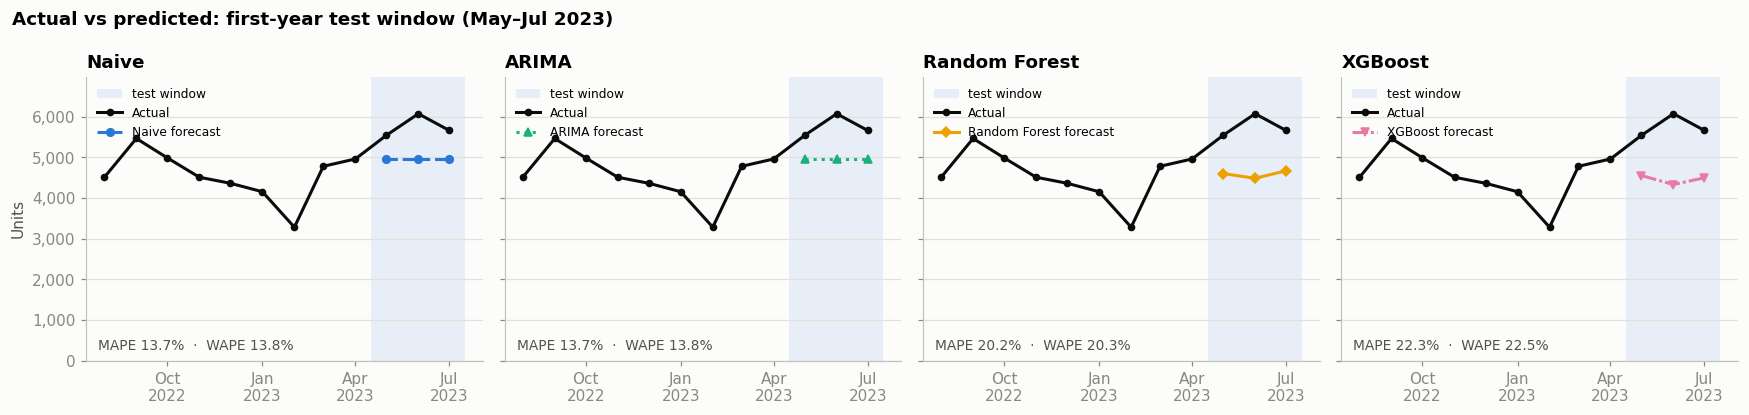

In [23]:
evaluated = [k for k in MODEL_ORDER if res_fy["models"][k]["evaluated"]]
fig, axes = plt.subplots(1, len(evaluated), figsize=(4.0 * len(evaluated), 3.8), sharey=True)
months_all = res_fy["actual"]["months"]
for ax, key in zip(axes, evaluated):
    m = res_fy["models"][key]
    shade(ax, res_fy["meta"]["test_months"], PALETTE["test"], "test window")
    ax.plot(month_ts(months_all), res_fy["actual"]["units"], color=PALETTE["actual"], marker="o", markersize=4, label="Actual")
    plot_model(ax, key, m["test"]["months"], m["test"]["predicted"], label=f"{m['label']} forecast")
    w = m["test"]["metrics"]["wape"]["value"]; mp = m["test"]["metrics"]["mape"]["value"]
    style_axes(ax, m["label"], ylabel="Units" if key == evaluated[0] else "", xlabel="")
    ax.text(0.03, 0.04, f"MAPE {mp:.1f}%  ·  WAPE {w:.1f}%", transform=ax.transAxes, fontsize=9, color=PALETTE["ink2"])
    ax.set_ylim(0, max(res_fy["actual"]["units"]) * 1.15)
    ax.legend(loc="upper left", fontsize=8)
fig.suptitle("Actual vs predicted: first-year test window (May–Jul 2023)", x=0.01, ha="left", fontweight="bold")
plt.tight_layout(); plt.show()

### MAPE and WAPE compared

Both metrics are shown for each evaluated model, with the same model colours as before. Lower is better.

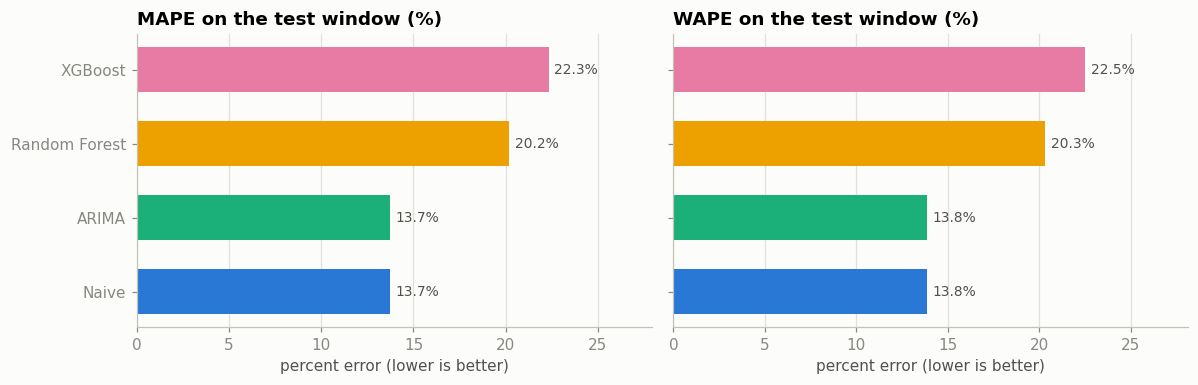

In [24]:
keys = [k for k in MODEL_ORDER if res_fy["models"][k]["evaluated"]]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for ax, metric in zip(axes, ["MAPE (%)", "WAPE (%)"]):
    field = "mape" if metric.startswith("MAPE") else "wape"
    vals = [res_fy["models"][k]["test"]["metrics"][field]["value"] for k in keys]   # raw values, rounded once
    bars = ax.barh([MODEL_LABELS[k] for k in keys], vals, color=[PALETTE[k] for k in keys], height=0.6)
    for bar, v in zip(bars, vals):
        ax.text(bar.get_width() + 0.3, bar.get_y() + bar.get_height() / 2, f"{v:.1f}%", va="center", fontsize=9,
                color=PALETTE["ink2"])
    ax.set_title(metric.replace(" (%)", " on the test window (%)"))
    ax.set_xlabel("percent error (lower is better)")
    ax.grid(axis="x"); ax.grid(axis="y", visible=False)
    ax.invert_yaxis()
    ax.set_xlim(0, max(vals) * 1.25)
plt.tight_layout(); plt.show()

**Reading the test results.**

* **Naive and ARIMA tie for best:** MAPE 13.7%, WAPE 13.8%. This is not a coincidence. On 9 training points the AICc search picked **ARIMA(0,1,0)**, a pure random walk, which forecasts exactly the last value, just like Naive. With so little data the extra ARIMA parameters (autoregression, moving average, drift) did not earn their keep under the small-sample penalty.
* **Random Forest (WAPE 20.3%) and XGBoost (22.5%) did worse.**
  * §6 showed that at series level last month barely predicts this month, so the trees had little to learn from the lags.
  * Their test forecasts, about 4,590 and 4,460 a month, sit close to the **average of the training months (about 4,560)**. The summer surge was never in their training data, so they could not produce it.
  * Both **under-forecast**, with biases of −20.3% and −22.5%.
* **Every model under-forecast the test window:** the best bias is −13.8%. No model had seen a full summer, so none could anticipate the June peak. For operations, a plan built on any of these forecasts would have **run short of stock in summer 2023**.
* **Seasonal Naive could not be scored**, because it needs 12 months before the test window. It becomes available as the data grows (§13).

## 11. Forecast the next three months (Task 4)

Each model is now **refit on all 12 months** and forecasts August–October 2023, with 80% and 95% uncertainty ranges where the model provides them:
* **Naive and Seasonal Naive:** analytic intervals.
* **ARIMA:** model-based intervals.
* **Random Forest:** a heuristic spread across its trees.
* **XGBoost:** a point forecast only.

In [25]:
rows = []
for key in MODEL_ORDER:
    fc = res_fy["models"][key]["forecast"]
    if not fc:
        continue
    for i, month in enumerate(fc["months"]):
        rows.append({"model": MODEL_LABELS[key], "month": month, "forecast": round(fc["point"][i]),
                     "80% low": None if fc["lo80"] is None else round(fc["lo80"][i]),
                     "80% high": None if fc["hi80"] is None else round(fc["hi80"][i]),
                     "95% low": None if fc["lo95"] is None else round(fc["lo95"][i]),
                     "95% high": None if fc["hi95"] is None else round(fc["hi95"][i])})
forecast_table = pd.DataFrame(rows).set_index(["model", "month"])
display(forecast_table)
print("Seasonal Naive's forecast is shown but was not evaluated on the test window (first year has too little history).")

forecast  80% low  80% high  95% low  95% high
model          month                                                  
Naive          2023-08      5661   4776.0    6546.0   4308.0    7014.0
               2023-09      5661   4410.0    6912.0   3747.0    7575.0
               2023-10      5661   4128.0    7194.0   3317.0    8005.0
Seasonal Naive 2023-08      4510      NaN       NaN      NaN       NaN
               2023-09      5464      NaN       NaN      NaN       NaN
               2023-10      4988      NaN       NaN      NaN       NaN
ARIMA          2023-08      5661   4779.0    6543.0   4312.0    7010.0
               2023-09      5661   4414.0    6908.0   3754.0    7568.0
               2023-10      5661   4134.0    7188.0   3325.0    7997.0
Random Forest  2023-08      5528   4397.0    6256.0   4146.0    6458.0
               2023-09      5355   4321.0    6448.0   4089.0    6655.0
               2023-10      5013   4088.0    6237.0   2790.0    6687.0
XGBoost        2023-08      5846      NaN       NaN      NaN       NaN
               2023-09      5916      NaN       NaN      NaN       NaN
               2023-10      5896      NaN       NaN      NaN       NaN

Seasonal Naive's forecast is shown but was not evaluated on the test window (first year has too little history).


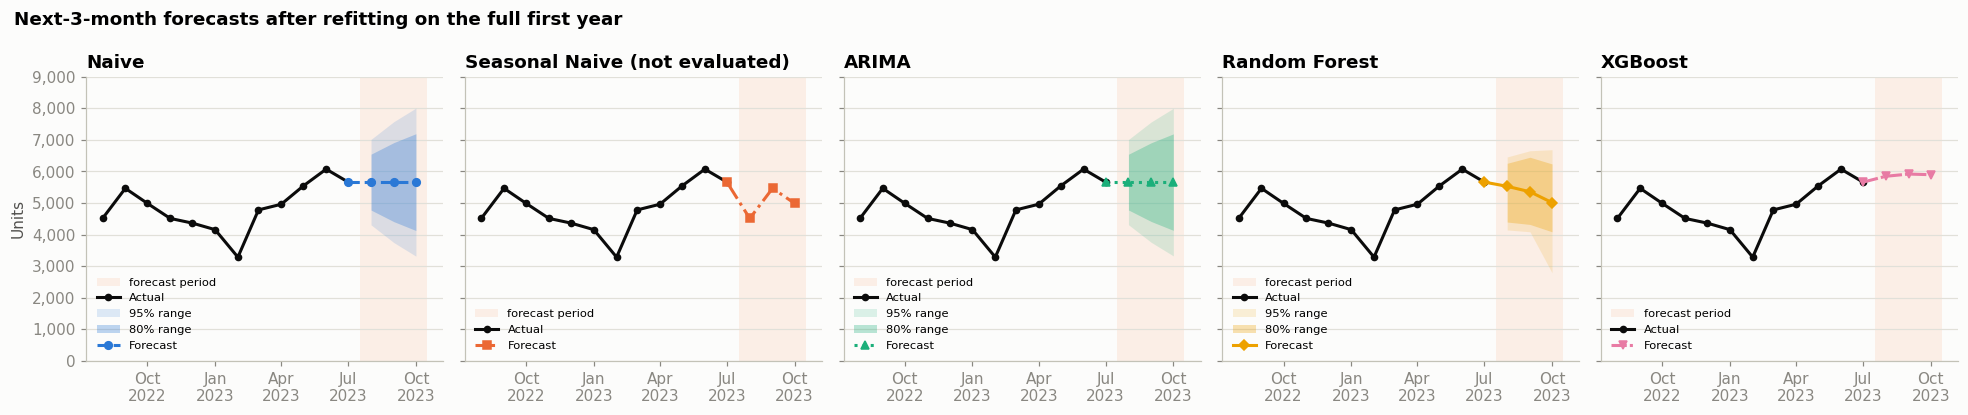

In [26]:
keys_fc = [k for k in MODEL_ORDER if res_fy["models"][k]["forecast"]]
fig, axes = plt.subplots(1, len(keys_fc), figsize=(3.6 * len(keys_fc), 3.8), sharey=True)
hist_months = res_fy["actual"]["months"]
for ax, key in zip(axes, keys_fc):
    fc = res_fy["models"][key]["forecast"]
    ts = month_ts([hist_months[-1]] + fc["months"])
    shade(ax, fc["months"], PALETTE["future"], "forecast period")
    ax.plot(month_ts(hist_months), res_fy["actual"]["units"], color=PALETTE["actual"], marker="o", markersize=4, label="Actual")
    if fc["lo95"] is not None:
        ax.fill_between(ts[1:], fc["lo95"], fc["hi95"], color=PALETTE[key], alpha=0.15, lw=0, label="95% range")
        ax.fill_between(ts[1:], fc["lo80"], fc["hi80"], color=PALETTE[key], alpha=0.30, lw=0, label="80% range")
    plot_model(ax, key, [hist_months[-1]] + fc["months"], [res_fy["actual"]["units"][-1]] + fc["point"], label="Forecast")
    title = MODEL_LABELS[key] + (" (not evaluated)" if not res_fy["models"][key]["evaluated"] else "")
    style_axes(ax, title, ylabel="Units" if key == keys_fc[0] else "", xlabel="")
    ax.set_ylim(0, 9000)
    ax.legend(loc="lower left", fontsize=7.5)
fig.suptitle("Next-3-month forecasts after refitting on the full first year", x=0.01, ha="left", fontweight="bold")
plt.tight_layout(); plt.show()

**What the ML models relied on.** Feature importance from the refitted Random Forest and XGBoost: the share of the models' splitting gain that each feature accounts for.

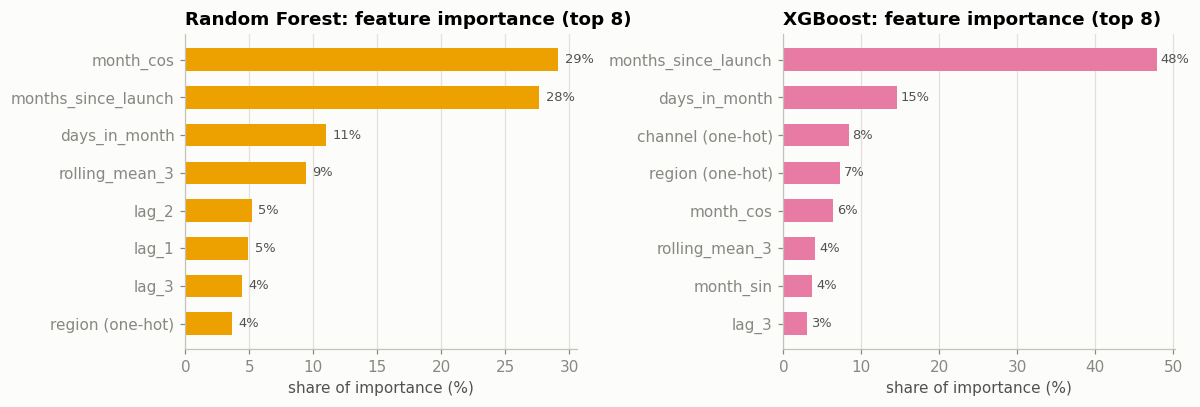

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, key in zip(axes, ("rf", "xgb")):
    imp = pd.DataFrame(res_fy["models"][key]["info"]["importance"]).head(8).iloc[::-1]
    ax.barh(imp["feature"], imp["importance"] * 100, color=PALETTE[key], height=0.6)
    for y, v in enumerate(imp["importance"] * 100):
        ax.text(v + 0.5, y, f"{v:.0f}%", va="center", fontsize=8.5, color=PALETTE["ink2"])
    ax.set_title(f"{MODEL_LABELS[key]}: feature importance (top 8)")
    ax.set_xlabel("share of importance (%)"); ax.grid(axis="x"); ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

**Reading the forecasts.**
* **Naive and ARIMA(0,1,0)** project July's level (5,661 a month) flat, with a range that widens each month. **Seasonal Naive** repeats last August–October (4,510, 5,464 and 4,988), which mostly reflects the *launch* months. **Random Forest** expects a gentle decline, while **XGBoost** stays near the summer level.
* **They disagree because they read the past differently.** Each answers "what happens after the first summer?" from a single year. The spread between them is itself a measure of how uncertain the outlook is.
* **The ML models leaned on calendar position and product age, not on lags.** Random Forest's top inputs are `month_cos` and `months_since_launch`; XGBoost's are `months_since_launch` and `days_in_month`. The lags rank low, consistent with the near-zero series-level lag correlation in §6.
* **What those inputs actually learned is the first year's shape, not seasonality.** Within one year, "position in the year" and "age of the product" describe the same 12 months. The models have learned *this* year's ups and downs. Whether they repeat cannot be known yet.

## 12. Analyst interpretation of the first-year results (Task 7)

**1. How well did the models capture seasonality and trends?**
* **Trend: partly.** All models track the recent *level* (persistence works).
* **Seasonality: not at all.** With one year, every calendar month has been seen once and is mixed up with the launch effect, so no model knew that summer brings a surge. All five under-forecast May–July 2023 (best bias −13.8%).

**2. Which model performed best, and why?** **Naive, tied with ARIMA(0,1,0).**
* Both scored WAPE 13.8% and MAPE 13.7%. On 9 data points the simplest assumption, that next month looks like the latest month, was the hardest to beat.
* ARIMA's order search independently landed on the same random walk.
* The ML models (WAPE 20–23%) had noisy series-level inputs and fell back towards the training average. They could not anticipate a summer rise they had never seen.

**3. Recommendations at this point:**
* Plan production from the simple forecast, but keep a buffer up to the upper uncertainty bound.
* Allocate stock by each region and channel's recent share.
* Re-forecast every month as new sales arrive.
* Don't trust any model's view of seasonality until about two years of history exist.

§13 tests that last recommendation by letting the following months arrive.

## 13. Real-time data: the following 17 months arrive one at a time

The slide asks for an interpretation "based on real-time data". We treat **real-time** as *whatever data exists at the moment the analysis is run*: each month the company closes its sales books, and the new month becomes available.

The 17 held-back months (Aug 2023 – Dec 2024) are revealed one by one. After each new month the full pipeline is re-run, keeping the same 3-month test window (always the latest 3 months) and the same 3-month horizon. Every forecast is also **logged**, so it can be scored against the actual figure when that arrives. This is exactly what the dashboard does when the user clicks *Next month*.

In [28]:
replay, tracking_log = [], []
t0 = time.perf_counter()
for k in range(FIRST_YEAR_MONTHS, len(panel["months"]) + 1):
    step = run_scenario(slice_panel(panel, k), {"level": "total", "test_size": 3, "horizon": 3,
                                                "tracking_log": tracking_log})
    tracking_log += step["new_log_entries"]
    replay.append(step)
print(f"{len(replay)} scenarios (data through {replay[0]['meta']['data_through']} ... "
      f"{replay[-1]['meta']['data_through']}) in {time.perf_counter() - t0:.1f}s; "
      f"{len(tracking_log)} forecasts logged.")

evolution = pd.DataFrame({
    "data through": [s["meta"]["data_through"] for s in replay],
    "months": [s["meta"]["n_months"] for s in replay],
    **{MODEL_LABELS[k]: [s["models"][k]["test"]["metrics"]["wape"]["value"] if s["models"][k]["evaluated"] else np.nan
                         for s in replay] for k in MODEL_ORDER},
    "best": [" / ".join(MODEL_LABELS[b] for b in s["best_models"]) for s in replay],
    "ARIMA chosen": [s["models"]["arima"]["info"].get("label") for s in replay],
}).set_index("data through")
display(evolution.round(1))

# Figures quoted in the reading below (kept honest by assertion).
ev = evolution.round(1)
assert (ev.loc["2024-12", "Seasonal Naive"], ev.loc["2024-12", "ARIMA"], ev.loc["2024-12", "Naive"]) == (1.4, 1.6, 22.1)
assert ev.loc["2023-11":"2024-01", "Seasonal Naive"].between(49, 58).all()
assert set(evolution.loc["2024-03":"2024-09", "best"]) <= {"XGBoost", "Random Forest"}
assert replay[12]["models"]["arima"]["info"]["label"] == "ARIMA(0,1,0)(0,1,0)[12]"     # data through 2024-07

18 scenarios (data through 2023-07 ... 2024-12) in 15.1s; 270 forecasts logged.


,months,Naive,Seasonal Naive,ARIMA,Random Forest,XGBoost,best,ARIMA chosen
data through,,,,,,,,
2023-07,12,13.8,NaN,13.8,20.3,22.5,Naive / ARIMA,"ARIMA(0,1,0)"
2023-08,13,9.7,NaN,9.7,9.7,10.6,Random Forest / Naive / ARIMA,"ARIMA(0,1,0)"
2023-09,14,30.5,NaN,30.5,21.7,24.9,Random Forest,"ARIMA(0,1,0)"
2023-10,15,43.9,28.4,43.9,34.6,49.6,Seasonal Naive,"ARIMA(0,1,0)"
2023-11,16,37.6,49.0,37.6,33.8,38.9,Random Forest,"ARIMA(0,1,0)"
2023-12,17,23.3,54.6,23.3,42.8,30.6,Naive / ARIMA,"ARIMA(0,1,0)"
2024-01,18,27.6,57.8,27.6,44.0,42.8,Naive / ARIMA,"ARIMA(0,1,0)"
2024-02,19,3.6,42.5,3.6,5.7,28.4,Naive / ARIMA,"ARIMA(0,1,0)"
2024-03,20,18.5,27.0,18.5,21.4,11.5,XGBoost,"ARIMA(0,1,0)"


### How each model's test-window error evolves as data arrives

At every step the test window is the latest 3 months, so each point is a fresh out-of-sample test. The vertical line marks **24 months**. From there on, seasonal ARIMA and the `lag_12` feature are switched on.

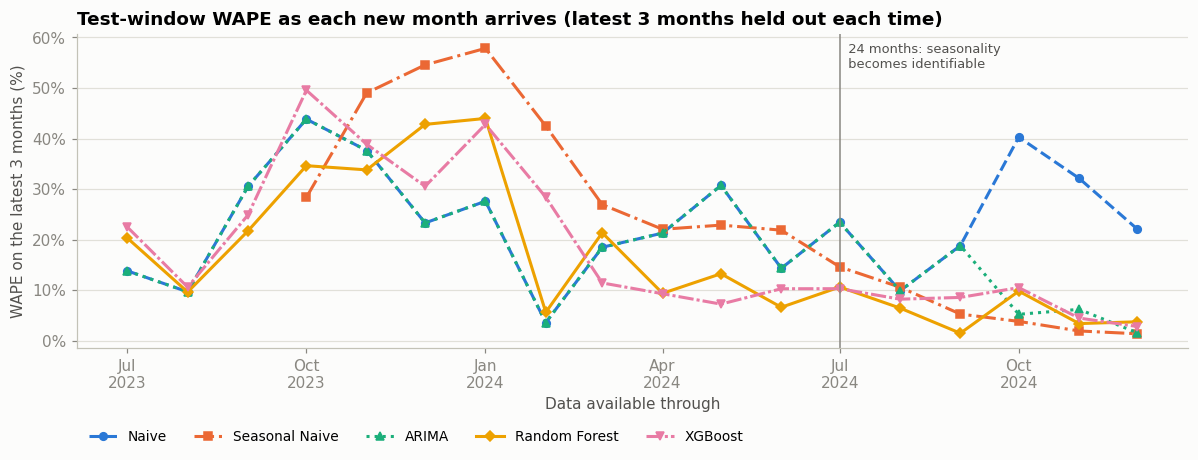

In [29]:
fig, ax = plt.subplots(figsize=(11, 4.4))
x = month_ts(evolution.index)
for key in MODEL_ORDER:
    ax.plot(x, evolution[MODEL_LABELS[key]], label=MODEL_LABELS[key], markersize=5, **STYLE[key])
ts24 = month_ts([panel["months"][23]])[0]
ax.axvline(ts24, color=PALETTE["muted"], lw=1)
ax.text(ts24, ax.get_ylim()[1] * 0.97, "  24 months: seasonality\n  becomes identifiable", va="top", fontsize=8.5,
        color=PALETTE["ink2"])
style_axes(ax, "Test-window WAPE as each new month arrives (latest 3 months held out each time)",
           ylabel="WAPE on the latest 3 months (%)", xlabel="Data available through")
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.0f}%"))
ax.legend(ncol=5, loc="upper left", bbox_to_anchor=(0, -0.22))
plt.tight_layout(); plt.show()

**Reading.**
* **The first autumn after the first year was the hardest period for every model.** After summer 2023 sales fell from 5,661 (July) to 2,615 (December), far below the launch-year autumn. For the test windows ending October 2023 to January 2024, most models' WAPE was between 23% and 58%.
* **Seasonal Naive was the worst model in winter 2023/24** (WAPE 49–58%). "Same month last year" meant copying autumn 2022, when launch hype kept sales far higher. Its only reference year was the launch year, so it over-forecast.
* **The pooled ML models improved first.** From spring 2024, Random Forest and XGBoost had 20–26 months of data and the extra `lag_3` and `rolling_mean_3` features. They won **every** test window from March to September 2024, with the best WAPE between 1.5% and 11.5%.
* **Once 24 months existed (data through July 2024), seasonality became identifiable.**
  * ARIMA switched to **ARIMA(0,1,0)(0,1,0)[12]**, a seasonal random walk.
  * In the final window (Oct–Dec 2024), **Seasonal Naive (WAPE 1.4%) and seasonal ARIMA (1.6%)** were the most accurate.
  * Naive, which knows nothing about seasons, was the least accurate (22.1%): it carried autumn levels into the winter decline.
* Until July 2024 ARIMA's line lies exactly on Naive's, because it kept choosing the plain random walk.

### Forecasts made in real time vs what actually happened

Each panel shows the actual sales over the full period in black, and the **one-month-ahead forecasts** a model made at each point in time: the forecast for month *t + 1* made with data up to month *t*. This is the "forecast tracking" log the dashboard keeps.

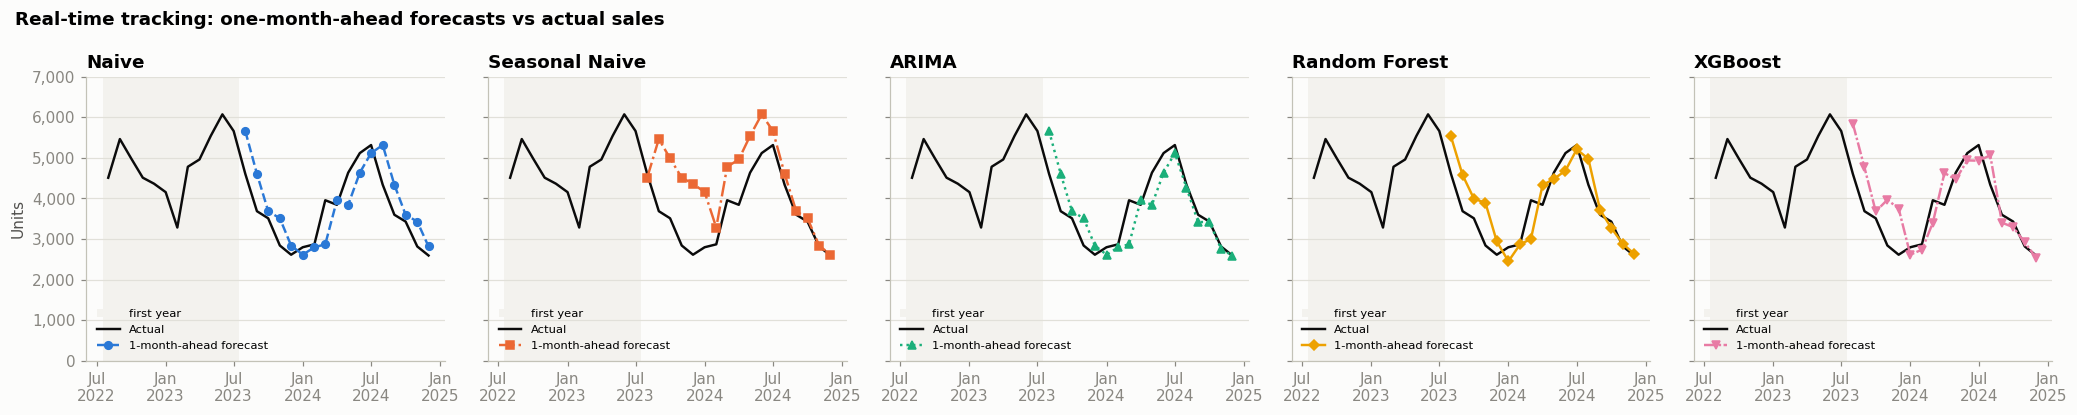

In [30]:
actual_all = panel_frame(panel).sum(axis=1)
log_df = pd.DataFrame(tracking_log)
one_step = log_df[log_df["step"] == 1]
fig, axes = plt.subplots(1, 5, figsize=(19, 3.8), sharey=True)
for ax, key in zip(axes, MODEL_ORDER):
    sub = one_step[(one_step["model"] == key) & (one_step["target"].isin([str(m) for m in actual_all.index]))]
    shade(ax, panel["months"][:FIRST_YEAR_MONTHS], PALETTE["train"], "first year")
    ax.plot(month_ts(actual_all.index), actual_all.values, color=PALETTE["actual"], lw=1.6, label="Actual")
    plot_model(ax, key, sub["target"], sub["forecast"], label="1-month-ahead forecast", lw=1.6)
    style_axes(ax, MODEL_LABELS[key], ylabel="Units" if key == "naive" else "", xlabel="")
    ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 7]))     # fewer ticks in narrow panels
    ax.set_ylim(0, 7000); ax.legend(loc="lower left", fontsize=7.5)
fig.suptitle("Real-time tracking: one-month-ahead forecasts vs actual sales", x=0.01, ha="left", fontweight="bold")
plt.tight_layout(); plt.show()

### Seasonality, now visible

With 29 months the same calendar months can finally be compared year on year. This chart would have been impossible in August 2023.

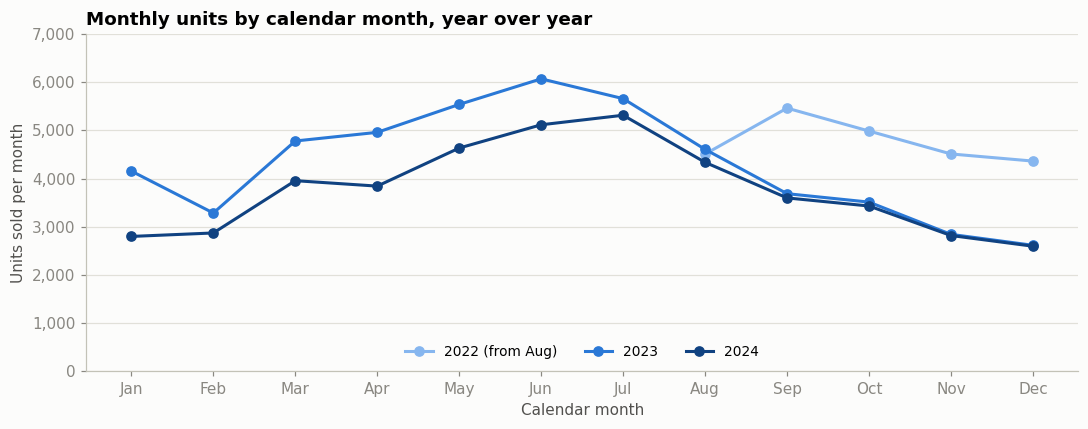

,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
2023,4156.0,3285.0,4781.0,4961.0,5541.0,6072.0,5661.0,4607.0,3687.0,3512.0,2842.0,2615.0
2024,2799.0,2871.0,3957.0,3844.0,4635.0,5118.0,5316.0,4338.0,3599.0,3431.0,2818.0,2596.0
change 2024 vs 2023 (%),-32.7,-12.6,-17.2,-22.5,-16.4,-15.7,-6.1,-5.8,-2.4,-2.3,-0.8,-0.7


In [31]:
fig, ax = plt.subplots(figsize=(10, 4))
ramp = {2022: "#86b6ef", 2023: "#2a78d6", 2024: "#104281"}       # ordinal blue ramp (older = lighter)
for year, color in ramp.items():
    s = actual_all[[p.year == year for p in actual_all.index]]
    ax.plot([p.month for p in s.index], s.values, color=color, marker="o", label=str(year) + (" (from Aug)" if year == 2022 else ""))
ax.set_xticks(range(1, 13)); ax.set_xticklabels(["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax.set_title("Monthly units by calendar month, year over year"); ax.set_ylabel("Units sold per month"); ax.set_xlabel("Calendar month")
ax.set_ylim(0, 7000); ax.legend(loc="lower center", ncol=3)
plt.tight_layout(); plt.show()
yoy = pd.DataFrame({"2023": actual_all[[p.year == 2023 for p in actual_all.index]].values,
                    "2024": actual_all[[p.year == 2024 for p in actual_all.index]].values},
                   index=["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
yoy["change 2024 vs 2023 (%)"] = (100 * (yoy["2024"] / yoy["2023"] - 1)).round(1)
display(yoy.T)

**Reading.**
* **The seasonal shape repeats.** In both years sales peak in June–July and bottom out between December and February.
* **The level reset after launch.** 2024 ran below 2023 in every month, but the gap narrowed steadily: from −32.7% in January to −0.7% in December. The launch boost faded, and the product settled at a lower, *mature* level. By late 2024 it was tracking the previous year almost exactly.
* **This is why first-year models had no chance.** During the first year, seasonality (summer up, winter down) and the launch effect (early hype fading) moved together. Only the second year revealed which part repeats.

## 14. Robustness: tracked accuracy and honest uncertainty ranges

A single 3-month test window is a small sample. The tracking log provides many more out-of-sample checks: every forecast made during the replay is scored once its actual month arrives. It also tests whether the **uncertainty ranges are honest**. An 80% range should contain the actual value about 80% of the time.

In [32]:
final = replay[-1]
trk = pd.DataFrame(final["tracking"]["by_model"]).set_index("label")
trk = trk[["n_points", "wape_pct", "mape_pct", "bias_pct", "coverage80_pct", "coverage95_pct"]]
trk.columns = ["forecasts scored", "WAPE (%)", "MAPE (%)", "bias (%)", "80% range hit rate (%)", "95% range hit rate (%)"]
display(trk.round(1))
avg_test = evolution[[MODEL_LABELS[k] for k in MODEL_ORDER]].mean().round(1).rename("mean test-window WAPE over the replay (%)")
display(avg_test.to_frame())
t = trk.round(1)
assert t["WAPE (%)"].idxmin() == "Random Forest" and t.loc["Random Forest", "WAPE (%)"] == 14.8
assert t.loc["ARIMA", "80% range hit rate (%)"] == 83.3 and t.loc["Random Forest", "80% range hit rate (%)"] == 68.8

,forecasts scored,WAPE (%),MAPE (%),bias (%),80% range hit rate (%),95% range hit rate (%)
label,,,,,,
Naive,48,24.2,24.8,7.5,75.0,97.9
Seasonal Naive,48,21.5,23.2,21.4,97.4,100.0
ARIMA,48,18.5,18.2,0.1,83.3,97.9
Random Forest,48,14.8,15.8,5.8,68.8,83.3
XGBoost,48,16.5,17.7,8.5,NaN,NaN


,mean test-window WAPE over the replay (%)
Naive,23.4
Seasonal Naive,24.3
ARIMA,18.9
Random Forest,16.6
XGBoost,18.4


**Reading.**
* **The long-run ranking differs from the single first-year test.** Over 48 scored forecasts per model:
  * **Random Forest** has the lowest error (WAPE 14.8%; mean test-window WAPE across the replay 16.6%).
  * XGBoost (16.5%) and ARIMA (18.5%) come next.
  * Seasonal Naive (21.5%) and Naive (24.2%) trail.

  The first-year test, where Naive won, was not representative of the long run. That is exactly why one 3-month test window should not be the only evidence for choosing a model.
* **Bias.** ARIMA is almost unbiased (+0.1%). Seasonal Naive over-forecast by 21.4% on average: for its first year of use, "same month last year" meant the launch-hype months.
* **Do the uncertainty ranges hold?** An 80% range should contain the actual value about 80% of the time:
  * **ARIMA: 83.3%.** Well calibrated.
  * **Naive: 75.0%.** Close.
  * **Seasonal Naive: 97.4%.** Its ranges are too wide.
  * **Random Forest: 68.8%.** Its tree-spread band is too narrow, as expected for a heuristic.
* **Practical conclusion.**
  * Size safety stock from **ARIMA's** ranges, not from Random Forest's band.
  * Judge models by their **running track record**, not by one test window.

## 15. LLM interpretation based on real-time data (Task 7 and the LLM requirement)

### Engine code: facts, rule-based fallback and grounding check

The LLM never sees the raw data and never computes anything itself. It receives a compact **facts** document: every number it is allowed to quote, already rounded (whole units; percentages to one decimal). Three functions sit around that document:

* `build_facts` assembles the document from a scenario result. The same function runs in this notebook and in the dashboard.
* `rule_based_interpretation` answers the same three questions from the same facts with fixed rules. It is the **fallback** when the LLM is unavailable, rate-limited or fails validation, so an interpretation is always available.
* `grounding_check` extracts every number from an interpretation and confirms it appears in the facts, allowing only for the rounding actually written. Dates, years and small counts (0–24) are allowed as-is. It also checks that every cited evidence key exists. Any figure it cannot verify is reported, so an invented number can't pass unnoticed.

In [33]:
def _r1(x):
    return None if x is None else round_half_up(x, 1)


def _ru(x):
    return None if x is None else int(round_half_up(x, 0))


def fmt_units(x) -> str:
    return "n/a" if x is None else f"{int(x):,}"


def fmt_pct(x, signed: bool = False) -> str:
    if x is None:
        return "n/a"
    return f"{x:+.1f}%" if signed else f"{x:.1f}%"


def build_facts(result: dict) -> dict:
    """Compact, rounded facts that the interpretation (LLM or rules) is allowed to use."""
    meta, trend, seas = result["meta"], result["trend"], result["seasonality"]
    facts = {
        "context": {
            "product": "New flavored water (proxy series: SKU JU-021, a juice, in a synthetic FMCG dataset)",
            "markets": list(REGIONS), "channels": list(CHANNELS),
            "level": meta["level_label"], "level_key": meta["level"],
            "launch_month": meta["launch_month"], "first_full_month": meta["months"][0],
            "data_through": meta["data_through"], "months_of_data": meta["n_months"],
            "months_after_first_year": max(0, meta["n_months"] - meta["first_year_months"]),
            "user_added_months": meta["user_added"], "user_modified_months": meta["user_modified"],
            "seasonality_identifiable": meta["seasonality_identifiable"],
            "months_needed_for_seasonality": SEASONAL_MIN_TRAIN,
        },
        "split": {
            "train_start": meta["train_months"][0], "train_end": meta["train_months"][-1],
            "train_months": meta["n_train"], "test_start": meta["test_months"][0],
            "test_end": meta["test_months"][-1], "test_months": meta["n_test"],
            "horizon_months": meta["horizon"], "forecast_months": meta["future_months"],
        },
        "recent_actuals": [{"month": m, "units": _ru(v)}
                           for m, v in list(zip(result["actual"]["months"], result["actual"]["units"]))[-12:]],
        "trend": {
            "latest_month": trend["latest_month"], "latest_units": _ru(trend["latest_units"]),
            "mom_change_pct": _r1(trend["mom_change_pct"]),
            "last3_avg_units": _ru(trend["last3_avg_units"]), "prev3_avg_units": _ru(trend["prev3_avg_units"]),
            "last3_vs_prev3_pct": _r1(trend["last3_vs_prev3_pct"]),
            "first3_avg_units": _ru(trend["first3_avg_units"]),
            "growth_vs_first3_pct": _r1(trend["growth_vs_first3_pct"]),
            "peak_month": trend["peak_month"], "peak_units": _ru(trend["peak_units"]),
            "low_month": trend["low_month"], "low_units": _ru(trend["low_units"]),
            "yoy_latest_pct": _r1(trend["yoy_latest_pct"]),
        },
        "seasonality": {
            "identifiable": seas["identifiable"],
            "calendar_months_seen_twice": seas["calendar_months_seen_twice"],
            "summer_avg_units": _ru(seas["summer_avg_units"]), "winter_avg_units": _ru(seas["winter_avg_units"]),
            "summer_vs_winter_pct": _r1(seas["summer_vs_winter_pct"]),
        },
        "models": {},
        "ranking": [{"rank": r["rank"], "model": r["model"], "label": r["label"],
                     "wape_pct": _r1(r["wape_pct"]), "mape_pct": _r1(r["mape_pct"])} for r in result["ranking"]],
        "best_models": list(result["best_models"]),
        "regions": [{"region": r["region"], "units_last3": _ru(r["units_last3"]),
                     "share_last3_pct": _r1(r["share_last3_pct"]),
                     "change_last3_vs_prev3_pct": _r1(r["change_last3_vs_prev3_pct"])} for r in result["regions"]],
        "channels": [{"channel": r["channel"], "units_last3": _ru(r["units_last3"]),
                      "share_last3_pct": _r1(r["share_last3_pct"]),
                      "change_last3_vs_prev3_pct": _r1(r["change_last3_vs_prev3_pct"])} for r in result["channels"]],
        "distribution_plan": None,
        "operations": None,
        "tracking": None,
    }
    for key in MODEL_ORDER:
        m = result["models"][key]
        entry = {"label": m["label"], "family": m["family"], "evaluated": m["evaluated"],
                 "not_evaluated_reason": m["not_evaluated_reason"]}
        if m["evaluated"]:
            met = m["test"]["metrics"]
            entry["test"] = {
                "wape_pct": _r1(met["wape"]["value"]), "mape_pct": _r1(met["mape"]["value"]),
                "bias_pct": _r1(met["bias"]["value"]), "abs_error_units": _ru(met["abs_error_units"]),
                "skill_vs_naive_pct": _r1(m["test"]["skill_vs_naive_pct"]),
                "identical_forecasts_to": [MODEL_LABELS[o] for o in m["test"]["identical_to"]],
                "per_month": [{"month": p["month"], "actual": _ru(p["actual"]), "forecast": _ru(p["forecast"])}
                              for p in met["per_month"]],
            }
        if m["forecast"]:
            fc = m["forecast"]
            entry["forecast"] = [
                {"month": fc["months"][i], "units": _ru(fc["point"][i]),
                 "lo80": _ru(fc["lo80"][i]) if fc["lo80"] else None, "hi80": _ru(fc["hi80"][i]) if fc["hi80"] else None,
                 "lo95": _ru(fc["lo95"][i]) if fc["lo95"] else None, "hi95": _ru(fc["hi95"][i]) if fc["hi95"] else None}
                for i in range(len(fc["months"]))]
            entry["forecast_total_units"] = _ru(sum(fc["point"]))
        else:
            entry["forecast"] = None
            entry["forecast_reason"] = m["forecast_reason"]
        if key == "arima" and m["info"].get("label"):
            entry["selected_model"] = m["info"]["label"]
        if key in ("rf", "xgb") and m["info"].get("training_rows"):
            entry["training_rows_test_fit"] = m["info"].get("test_fit", {}).get("training_rows")
            entry["training_rows_forecast_fit"] = m["info"]["training_rows"]
            entry["top_features"] = [d["feature"] for d in m["info"]["importance"][:3]]
            entry["interval"] = m["info"]["interval"]
        facts["models"][key] = entry
    dist = result["distribution"]
    if dist:
        by_region, by_channel = {}, {}
        for c in dist["cells"]:
            by_region[c["region"]] = by_region.get(c["region"], 0.0) + c["total"]
            by_channel[c["channel"]] = by_channel.get(c["channel"], 0.0) + c["total"]
        grand = sum(by_region.values()) or 1.0
        facts["distribution_plan"] = {
            "model": dist["label"], "method": dist["method"], "months": dist["months"],
            "total_units": _ru(grand),
            "by_region": [{"region": k, "units": _ru(v), "share_pct": _r1(100 * v / grand)} for k, v in by_region.items()],
            "by_channel": [{"channel": k, "units": _ru(v), "share_pct": _r1(100 * v / grand)} for k, v in by_channel.items()],
        }
    ops = result["operations"]
    if ops and ops["stockout_rows_last3"] is not None:
        facts["operations"] = {"stockout_rows_last3": _ru(ops["stockout_rows_last3"]),
                               "est_lost_units_last3": _ru(ops["est_lost_units_last3"]),
                               "promo_uplift_ratio": None if ops["promo_uplift_ratio"] is None else round_half_up(ops["promo_uplift_ratio"], 2),
                               "promo_share_pct": _r1(ops["promo_share_pct"])}
    trk = result["tracking"]
    if trk and trk["n_scored"]:
        facts["tracking"] = {"n_scored": trk["n_scored"],
                             "by_model": [{"model": b["model"], "label": b["label"], "n_points": b["n_points"],
                                           "wape_pct": _r1(b["wape_pct"]), "bias_pct": _r1(b["bias_pct"]),
                                           "coverage80_pct": _r1(b["coverage80_pct"])} for b in trk["by_model"]]}
    return facts


def _units_list(fc: list, field: str = "units") -> str:
    return ", ".join(f"{f['month']}: {fmt_units(f[field])}" for f in fc)


def rule_based_interpretation(facts: dict) -> dict:
    """Deterministic interpretation built only from facts (used when the LLM is unavailable)."""
    ctx, tr, se, models, ranking = (facts["context"], facts["trend"], facts["seasonality"],
                                    facts["models"], facts["ranking"])
    n = ctx["months_of_data"]

    # 1. Seasonality & trend ------------------------------------------------
    s1 = [f"The latest month ({tr['latest_month']}) sold {fmt_units(tr['latest_units'])} units"
          + (f" ({fmt_pct(tr['mom_change_pct'], True)} versus the previous month)" if tr["mom_change_pct"] is not None else "") + "."]
    ev1 = ["trend.latest_units", "trend.mom_change_pct"]
    if tr["last3_vs_prev3_pct"] is not None:
        s1.append(f"The last three months averaged {fmt_units(tr['last3_avg_units'])} units, "
                  f"{fmt_pct(tr['last3_vs_prev3_pct'], True)} versus the three months before; "
                  f"the peak so far was {tr['peak_month']} ({fmt_units(tr['peak_units'])} units).")
        ev1 += ["trend.last3_avg_units", "trend.last3_vs_prev3_pct", "trend.peak_units"]
    if se["summer_vs_winter_pct"] is not None:
        s1.append(f"Summer months averaged {fmt_units(se['summer_avg_units'])} units against "
                  f"{fmt_units(se['winter_avg_units'])} in winter ({fmt_pct(se['summer_vs_winter_pct'], True)}).")
        ev1 += ["seasonality.summer_avg_units", "seasonality.winter_avg_units", "seasonality.summer_vs_winter_pct"]
    if not se["identifiable"]:
        s1.append(f"With only {n} months of history, no calendar month has been seen often enough to separate "
                  f"seasonality from the launch ramp-up ({ctx['months_needed_for_seasonality']} months are needed), "
                  "so none of the models could learn the seasonal pattern yet; they extrapolate the recent level or trend.")
        ev1 += ["context.months_of_data", "seasonality.identifiable"]
    else:
        sn = models.get("snaive", {})
        s1.append(f"With {n} months, {se['calendar_months_seen_twice']} calendar months have been observed at least twice, "
                  "so seasonality is now estimable: Seasonal Naive"
                  + (f" (WAPE {fmt_pct(sn['test']['wape_pct'])})" if sn.get("evaluated") else "")
                  + f" and {models['arima'].get('selected_model', 'ARIMA')} use last year's pattern directly.")
        ev1 += ["seasonality.calendar_months_seen_twice", "models.arima.selected_model"]
    if ranking:
        b = models[ranking[0]["model"]]["test"]
        direction = "under" if (b["bias_pct"] or 0) < 0 else "over"
        s1.append(f"On the test window ({facts['split']['test_start']} to {facts['split']['test_end']}) the best model's bias "
                  f"was {fmt_pct(b['bias_pct'], True)}, i.e. it {direction}-forecast that period.")
        ev1.append(f"models.{ranking[0]['model']}.test.bias_pct")

    # 2. Best model & why ---------------------------------------------------
    s2, ev2 = [], []
    if not ranking:
        s2.append("No model could be evaluated on the current test window.")
    else:
        top = [r for r in ranking if r["rank"] == 1]
        top_keys = {r["model"] for r in top}
        lead = top[0]
        if len(top) > 1:
            labels = [r["label"] for r in top]
            joined = labels[0] if len(labels) == 1 else ", ".join(labels[:-1]) + " and " + labels[-1]
            s2.append(joined + f" tie for best with WAPE {fmt_pct(lead['wape_pct'])} "
                      f"(MAPE {fmt_pct(lead['mape_pct'])}) on the {facts['split']['test_months']}-month test window.")
        else:
            s2.append(f"{lead['label']} performed best on the {facts['split']['test_months']}-month test window with "
                      f"WAPE {fmt_pct(lead['wape_pct'])} (MAPE {fmt_pct(lead['mape_pct'])}).")
        ev2 += [f"ranking.0.wape_pct", "ranking.0.mape_pct"]
        ident = models["arima"].get("test", {}).get("identical_forecasts_to", []) if models["arima"]["evaluated"] else []
        if "Naive" in ident and top_keys & {"naive", "arima"}:      # only relevant when they lead
            s2.append(f"ARIMA chose {models['arima'].get('selected_model', 'a random walk')}, a random walk, so its forecasts are identical to Naive.")
            ev2.append("models.arima.test.identical_forecasts_to")
        family = models[lead["model"]]["family"]
        n_train = facts["split"]["train_months"]
        if family in ("baseline", "statistical") and lead["model"] != "snaive":
            ml = [models[k] for k in ("rf", "xgb") if models[k]["evaluated"]]
            if ml:
                biases = [m["test"]["bias_pct"] or 0 for m in ml]
                missed = ("under-forecast" if all(b < 0 for b in biases)
                          else "over-forecast" if all(b > 0 for b in biases) else "missed")
                s2.append(f"With only {n_train} training months the most reliable signal was the latest level. "
                          + " and ".join(f"{m['label']} (WAPE {fmt_pct(m['test']['wape_pct'])}, bias {fmt_pct(m['test']['bias_pct'], True)})" for m in ml)
                          + f" learned from {fmt_units(models['rf'].get('training_rows_test_fit'))} pooled rows but {missed} the test "
                          "window: with so little history they had seen few comparable months, and tree models cannot "
                          "extrapolate beyond the levels they were trained on.")
                ev2 += ["split.train_months", "models.rf.test.wape_pct", "models.xgb.test.wape_pct",
                        "models.rf.training_rows_test_fit"]
        elif lead["model"] == "snaive":
            s2.append("The same month last year was the best guide because the seasonal pattern repeats and the history now covers it.")
        else:
            m = models[lead["model"]]
            s2.append(f"{m['label']} pooled the 9 region-channel series ({fmt_units(m.get('training_rows_test_fit'))} training rows) "
                      f"and combined recent lags with calendar features; its most important inputs were "
                      f"{', '.join(m.get('top_features', []))}.")
            ev2 += [f"models.{lead['model']}.training_rows_test_fit", f"models.{lead['model']}.top_features"]
        skill = models[lead["model"]]["test"]["skill_vs_naive_pct"]
        if "naive" not in top_keys and skill is not None and skill > 0:   # no "better than Naive" when tied with it
            s2.append(f"It is {fmt_pct(skill)} more accurate than the Naive baseline.")
            ev2.append(f"models.{lead['model']}.test.skill_vs_naive_pct")
        worst = ranking[-1]
        if worst["model"] != lead["model"]:
            s2.append(f"{worst['label']} was weakest (WAPE {fmt_pct(worst['wape_pct'])}).")
            ev2.append(f"ranking.{len(ranking) - 1}.wape_pct")

    # 3. Recommendations ----------------------------------------------------
    recs = []
    if ranking:
        lead_key = ranking[0]["model"]
        plan_key = lead_key
        if models[lead_key].get("forecast") and models[lead_key]["forecast"][0]["hi80"] is None:
            plan_key = next((k for k in ("arima", "naive", "snaive", "rf") if models[k].get("forecast")
                             and models[k]["forecast"][0]["hi80"] is not None), lead_key)
        fc = models[lead_key].get("forecast")
        if fc:
            detail = (f"Plan production for {facts['split']['forecast_months'][0]} to {facts['split']['forecast_months'][-1]} "
                      f"around the {models[lead_key]['label']} forecast ({_units_list(fc)}; "
                      f"{fmt_units(models[lead_key]['forecast_total_units'])} units in total).")
            ev = [f"models.{lead_key}.forecast", f"models.{lead_key}.forecast_total_units"]
            pfc = models[plan_key].get("forecast")
            if pfc and pfc[0]["hi80"] is not None:
                detail += (f" Keep capacity or stock up to the {models[plan_key]['label']} 80% upper bound "
                           f"({_units_list(pfc, 'hi80')}) so a demand surprise does not cause stockouts.")
                ev.append(f"models.{plan_key}.forecast")
            recs.append({"title": "Production volume and buffer", "detail": detail, "evidence": ev})
    dp = facts.get("distribution_plan")
    if dp:
        regions = "; ".join(f"{r['region']} {fmt_units(r['units'])} units ({fmt_pct(r['share_pct'])})" for r in dp["by_region"])
        channels = "; ".join(f"{c['channel']} {fmt_pct(c['share_pct'])}" for c in dp["by_channel"])
        recs.append({"title": "Regional and channel allocation",
                     "detail": f"Allocate the {fmt_units(dp['total_units'])} planned units by region: {regions}. By channel: {channels}.",
                     "evidence": ["distribution_plan.by_region", "distribution_plan.by_channel", "distribution_plan.total_units"]})
    ops = facts.get("operations")
    if ops:
        text = (f"Stockouts cost an estimated {fmt_units(ops['est_lost_units_last3'])} units in the last three months "
                f"({fmt_units(ops['stockout_rows_last3'])} store-days out of stock); raise safety stock before peak months.")
        ev = ["operations.est_lost_units_last3", "operations.stockout_rows_last3"]
        if ops.get("promo_uplift_ratio"):
            text += (f" Promotion days sell {ops['promo_uplift_ratio']}x a normal day, so use promotions to lift off-season "
                     "demand rather than to add to the summer peak.")
            ev.append("operations.promo_uplift_ratio")
        recs.append({"title": "Availability and promotions", "detail": text, "evidence": ev})
    if not se["identifiable"]:
        recs.append({"title": "Re-forecast monthly",
                     "detail": (f"Re-run the forecast every month as actuals arrive (data currently runs to {ctx['data_through']}). "
                                f"Until {ctx['months_needed_for_seasonality']} months exist, use the simple model as the planning "
                                "baseline and treat machine-learning outputs as a cross-check."),
                     "evidence": ["context.data_through", "context.months_needed_for_seasonality"]})
    else:
        recs.append({"title": "Use the seasonal pattern",
                     "detail": ("Seasonality is now estimable: build stock ahead of the summer peak using the seasonal models, "
                                "and keep re-forecasting monthly."),
                     "evidence": ["seasonality.identifiable"]})
    trk = facts.get("tracking")
    if trk and trk["by_model"]:
        bt = min(trk["by_model"], key=lambda b: b["wape_pct"] if b["wape_pct"] is not None else 1e9)
        detail = (f"Across {trk['n_scored']} forecasts already scored against actuals, {bt['label']} has the "
                  f"lowest tracked WAPE ({fmt_pct(bt['wape_pct'])} over {bt['n_points']} forecasts).")
        if ranking and bt["model"] != ranking[0]["model"]:
            detail += (f" The latest test window favours {ranking[0]['label']} while the longer record favours "
                       f"{bt['label']}, so averaging the two forecasts is a sensible hedge.")
        recs.append({"title": "Trust the track record", "detail": detail,
                     "evidence": ["tracking.n_scored", "tracking.by_model"]})

    test_months = facts["split"]["test_months"]
    caveats = ["Synthetic data: SKU JU-021 (a juice) stands in for the flavored water, so patterns are illustrative.",
               (f"Short history: {n} months of data and a {test_months}-month test window make error estimates noisy."
                if not se["identifiable"] else
                f"Small test window: a single {test_months}-month test can rank models differently from their longer track record."),
               "Random Forest's range is a heuristic spread of its trees and XGBoost has no uncertainty range."]
    if ctx["user_added_months"] or ctx["user_modified_months"]:
        caveats.append("Includes user-entered or edited months: "
                       + ", ".join(sorted(set(ctx["user_added_months"]) | set(ctx["user_modified_months"]))) + ".")
    return {"seasonality_trend": {"answer": " ".join(s1), "evidence": ev1},
            "best_model": {"answer": " ".join(s2), "evidence": ev2},
            "recommendations": recs, "caveats": caveats}


_DATE_PATTERN = r"\b(?:19|20)\d{2}-(?:0[1-9]|1[0-2])(?:-\d{2})?\b"
_CODE_PATTERN = r"\b[A-Z]{2}-\d{3}\b"
_NUMBER_PATTERN = r"(?<![A-Za-z_\d.])[+\-−]?(?:\d{1,3}(?:,\d{3})+|\d+)(?:\.\d+)?"


def _numeric_leaves(obj, out: set):
    if isinstance(obj, bool) or obj is None:
        return
    if isinstance(obj, (int, float)):
        out.add(float(obj))
    elif isinstance(obj, dict):
        for v in obj.values():
            _numeric_leaves(v, out)
    elif isinstance(obj, (list, tuple)):
        for v in obj:
            _numeric_leaves(v, out)


def _path_exists(facts: dict, path: str) -> bool:
    node = facts
    for part in path.split("."):
        if isinstance(node, dict) and part in node:
            node = node[part]
        elif isinstance(node, list) and part.isdigit() and int(part) < len(node):
            node = node[int(part)]
        else:
            return False
    return True


def _texts(interp: dict) -> list:
    out = [interp["seasonality_trend"]["answer"], interp["best_model"]["answer"]]
    for r in interp["recommendations"]:
        out += [r["title"], r["detail"]]
    return out + list(interp["caveats"])


def _matches(token: str, known: set) -> bool:
    raw = token.replace(",", "").replace("−", "-").lstrip("+")
    value = float(raw)
    decimals = len(raw.split(".")[1]) if "." in raw else 0
    if decimals == 0 and float(value).is_integer() and (0 <= abs(value) <= 24 or 2020 <= value <= 2030 or abs(value) in (80, 95, 100)):
        return True
    candidates = known | {abs(k) for k in known}
    for f in candidates:
        if round_half_up(f, decimals) == abs(value) or round_half_up(f, decimals) == value:
            return True
        if decimals == 0:
            digits = raw.lstrip("-")
            zeros = len(digits) - len(digits.rstrip("0"))
            for k in range(1, min(zeros, 3) + 1):
                if abs(f) >= 10 ** k and round_half_up(abs(f), -k) == abs(value):
                    return True
    return False


def grounding_check(interp: dict, facts: dict) -> dict:
    """Every number in the interpretation must come from the facts; evidence keys must exist."""
    import re
    known = set()
    _numeric_leaves(facts, known)
    unverified = []
    checked = 0
    for text in _texts(interp):
        clean = re.sub(_DATE_PATTERN, " ", text)
        clean = re.sub(_CODE_PATTERN, " ", clean)
        for token in re.findall(_NUMBER_PATTERN, clean):
            checked += 1
            if not _matches(token, known):
                unverified.append(token)
    keys = [interp["seasonality_trend"]["evidence"], interp["best_model"]["evidence"]] + \
           [r["evidence"] for r in interp["recommendations"]]
    bad_keys = sorted({k for group in keys for k in group if not _path_exists(facts, k)})
    return {"numbers_checked": checked, "unverified_numbers": unverified, "invalid_evidence_keys": bad_keys,
            "passed": not unverified and not bad_keys}

### The prompt

The prompt is the contract with the LLM:
1. **Use only the numbers in the facts, quoted exactly as written.** The LLM may not compute, estimate or invent anything.
2. **Answer the slide's three questions** in a fixed JSON structure.
3. **Cite the facts used** for every answer, as dotted keys such as `models.naive.test.wape_pct`.

**Structured output.** A JSON schema guarantees the shape of the answer, so the notebook and the dashboard never have to parse free text.

**Single source.** The dashboard's server-side function uses this exact prompt and schema. They are exported from this cell, tagged `prompt`.

In [34]:
SYSTEM_PROMPT = """You are a demand-planning analyst writing for the operations team of a beverage company.
You interpret forecasting results for a newly launched flavored-water product sold in three regions and three sales channels.

You receive FACTS as JSON. They were computed by the forecasting engine from the data available right now.

Rules:
1. Use only numbers that appear in FACTS, and quote them exactly as written there (same rounding, same units).
   Never calculate new numbers (no sums, differences, averages or percentages of your own), never estimate, never invent.
2. If something is not in FACTS, say it is not available instead of guessing.
3. Refer to models by their labels: Naive, Seasonal Naive, ARIMA, Random Forest, XGBoost.
4. Answer these questions:
   - seasonality_trend: How well did the models capture seasonality and trends? Describe the trend and the seasonality
     visible in the data, and whether the models could learn them given the amount of history.
   - best_model: Which model performed best on the test window, and why? Use WAPE as the primary metric and also
     mention MAPE. If models tie or produce identical forecasts, say so and explain why.
   - recommendations: 3 to 5 concrete recommendations for production and distribution planning (volumes for the coming
     months, buffers based on the uncertainty range, regional and channel allocation, stockouts, promotions, when to
     re-forecast or switch models).
   - caveats: 2 to 4 short limitations (for example synthetic data, short history, small test window, user-edited data).
5. For every answer and recommendation, list in "evidence" the FACTS keys you used, written as dotted paths
   (for example "models.naive.test.wape_pct" or "trend.last3_vs_prev3_pct"); use numbers for list positions
   (for example "ranking.0.wape_pct").
6. Write plain business English for managers: 60 to 140 words per answer, 1 to 3 sentences per recommendation.
   No markdown headings and no tables."""

USER_TEMPLATE = """FACTS (JSON):
{facts_json}

Write the interpretation as JSON that matches the required schema."""

OUTPUT_SCHEMA = {
    "type": "object",
    "properties": {
        "seasonality_trend": {
            "type": "object",
            "properties": {"answer": {"type": "string"}, "evidence": {"type": "array", "items": {"type": "string"}}},
            "required": ["answer", "evidence"], "additionalProperties": False},
        "best_model": {
            "type": "object",
            "properties": {"answer": {"type": "string"}, "evidence": {"type": "array", "items": {"type": "string"}}},
            "required": ["answer", "evidence"], "additionalProperties": False},
        "recommendations": {
            "type": "array",
            "items": {"type": "object",
                      "properties": {"title": {"type": "string"}, "detail": {"type": "string"},
                                     "evidence": {"type": "array", "items": {"type": "string"}}},
                      "required": ["title", "detail", "evidence"], "additionalProperties": False}},
        "caveats": {"type": "array", "items": {"type": "string"}},
    },
    "required": ["seasonality_trend", "best_model", "recommendations", "caveats"],
    "additionalProperties": False,
}

### Calling the LLM, with fallbacks

`interpret()` tries the providers in order and always returns an interpretation:

1. **NVIDIA API Catalog (free).**
   * Get a free key at [build.nvidia.com](https://build.nvidia.com) and set it in the `NVIDIA_API_KEY` environment variable; it is never written in the notebook. In Colab, put it in *Secrets* and export it to the environment.
   * Five free models are asked at once, as in the dashboard: `nvidia/nemotron-3.5-lightning-30b-a3b`, `openai/gpt-oss-20b`, `deepseek-ai/deepseek-v4.1-flash`, `z-ai/glm-5.3-flash` and `nvidia/nemotron-3-super-120b-a12b`. The first answer that passes the grounding check wins; otherwise the answer with the fewest problems is used. The `LLM_MODEL` environment variable overrides the list, and a retired model (HTTP 404/410) simply drops out.
   * The endpoint is OpenAI-compatible and is called with the Python standard library. The models are asked to skip their slow thinking phase, and they receive the exact list of valid evidence keys.
2. **Claude through the Anthropic API** (paid; used if no NVIDIA key is set).
   * The default model is `claude-opus-5-5`; the `LLM_MODEL` environment variable overrides it.
   * The key is read from the `ANTHROPIC_API_KEY` environment variable and is never written in the notebook. In Colab, put it in *Secrets* and export it to the environment.
   * The call uses low effort, structured JSON output, and the API's server-side refusal fallback. If that beta option is rejected, it retries once without it.
3. **Google Colab's built-in AI**, which needs no key. This is the option shown in the class demo notebook, and it only works inside Colab.
4. **The rule-based interpretation** from §15's engine code, labelled as such.

Whichever source answers, the output then goes through the **grounding check**.

**In the saved run of this notebook no API key was configured**, so the interpretations below came from route 4, the labelled rule-based fallback. Set `NVIDIA_API_KEY` (free) or `ANTHROPIC_API_KEY` and re-run these cells to get an LLM interpretation. The facts and the checks stay the same, and the source line above each interpretation always says which route produced it.

In [35]:
import re

NVIDIA_URL = "https://integrate.api.nvidia.com/v1/chat/completions"
# Asked in parallel, as in the dashboard: the first fully grounded answer wins. NVIDIA retires catalog
# models over time (HTTP 404/410); a retired model simply drops out. LLM_MODEL may override the list.
NVIDIA_DEFAULT_MODELS = ("nvidia/nemotron-3.5-lightning-30b-a3b,openai/gpt-oss-20b,deepseek-ai/deepseek-v4.1-flash,"
                         "z-ai/glm-5.3-flash,nvidia/nemotron-3-super-120b-a12b")
NVIDIA_TIMEOUT_S = 180          # free endpoints can queue for a minute or more
CLAUDE_DEFAULT_MODEL = "claude-opus-5-5"


def facts_json(facts: dict) -> str:
    return json.dumps(facts, ensure_ascii=False, separators=(",", ":"))


def parse_interpretation(text: str) -> dict:
    """Parse and validate the JSON interpretation.

    Tolerates what open models add around it: a code fence, a <think>...</think> reasoning block,
    or a sentence before/after the JSON object.
    """
    text = re.sub(r"<think>.*?</think>", "", text, flags=re.S | re.I).strip()
    first, last = text.find("{"), text.rfind("}")
    if first < 0 or last <= first:
        raise ValueError("no JSON object in the answer")
    data = json.loads(text[first:last + 1])
    for k in ("seasonality_trend", "best_model"):
        if not isinstance(data[k]["answer"], str) or not isinstance(data[k]["evidence"], list):
            raise ValueError(f"bad field {k}")
    if not isinstance(data["recommendations"], list) or not data["recommendations"]:
        raise ValueError("no recommendations")
    for r in data["recommendations"]:
        if not all(isinstance(r[f], (str, list)) for f in ("title", "detail", "evidence")):
            raise ValueError("bad recommendation")
    if not isinstance(data["caveats"], list):
        raise ValueError("bad caveats")
    return data


def fact_paths(node, path=""):
    """Every leaf path in FACTS as a dotted key (list positions as numbers), as the grounding check reads them."""
    if isinstance(node, dict) or isinstance(node, list):
        items = list(node.items()) if isinstance(node, dict) else [(str(i), v) for i, v in enumerate(node)]
        if not items and path:
            return [path]
        out = []
        for key, value in items:
            out += fact_paths(value, f"{path}.{key}" if path else str(key))
        return out
    return [path] if path else []


def call_nvidia(facts: dict):
    """Free route: NVIDIA API Catalog (build.nvidia.com), OpenAI-compatible, standard library only.

    All models are asked at once (threads). The first answer that passes the grounding check wins;
    otherwise the answer with the fewest problems. Every model's outcome is reported if all fail.
    """
    import concurrent.futures as cf
    import urllib.error
    import urllib.request
    key = os.environ.get("NVIDIA_API_KEY", "").strip()
    if not key:
        return None, "NVIDIA_API_KEY is not set"
    models = [m.strip() for m in os.environ.get("LLM_MODEL", NVIDIA_DEFAULT_MODELS).split(",") if m.strip()]
    user = (USER_TEMPLATE.format(facts_json=facts_json(facts))
            + "\n\nReturn only a JSON object (no prose, no code fence) matching this JSON schema:\n"
            + json.dumps(OUTPUT_SCHEMA)
            # open models tend to guess evidence paths, so they get the exact list the check accepts
            + "\n\nValid evidence keys (copy them exactly; cite only keys from this list):\n"
            + ", ".join(fact_paths(facts)))

    def send(model: str, fast: bool) -> dict:
        body = {"model": model, "temperature": 0.2, "top_p": 0.9, "max_tokens": 3000, "stream": False,
                "messages": [{"role": "system", "content": SYSTEM_PROMPT}, {"role": "user", "content": user}]}
        if fast:   # skip the slow thinking phase where the model supports it
            body.update({"reasoning_effort": "low"} if model.startswith("openai/gpt-oss")
                        else {"chat_template_kwargs": {"thinking": False, "enable_thinking": False}})
        req = urllib.request.Request(NVIDIA_URL, data=json.dumps(body).encode(), method="POST", headers={
            "Authorization": f"Bearer {key}", "Content-Type": "application/json", "Accept": "application/json"})
        with urllib.request.urlopen(req, timeout=NVIDIA_TIMEOUT_S) as resp:
            return json.loads(resp.read())

    def ask(model: str):
        """Returns (interpretation, model id, problems) or raises RuntimeError with a short reason."""
        name = model.split("/")[-1]
        try:
            try:
                data = send(model, fast=True)
            except urllib.error.HTTPError as exc:
                if exc.code not in (400, 422):
                    raise
                data = send(model, fast=False)                 # model rejects the speed options
        except urllib.error.HTTPError as exc:
            reason = {401: "key rejected", 403: "key rejected", 404: "model retired", 410: "model retired",
                      429: "rate limited"}.get(exc.code, "API error")
            raise RuntimeError(f"{name}: {reason} (HTTP {exc.code})") from None
        except (urllib.error.URLError, TimeoutError, OSError):
            raise RuntimeError(f"{name}: no answer within {NVIDIA_TIMEOUT_S} s") from None
        choice = (data.get("choices") or [{}])[0]
        if choice.get("finish_reason") == "length":
            raise RuntimeError(f"{name}: answer cut off")
        try:
            interp = parse_interpretation((choice.get("message") or {}).get("content") or "")
        except (ValueError, KeyError, TypeError):
            raise RuntimeError(f"{name}: answer not in the expected JSON format") from None
        g = grounding_check(interp, facts)
        return interp, data.get("model", model), len(g["unverified_numbers"]) + len(g["invalid_evidence_keys"])

    best, failures = None, []
    pool = cf.ThreadPoolExecutor(max_workers=len(models))
    try:
        for future in cf.as_completed([pool.submit(ask, m) for m in models]):
            try:
                interp, model_id, problems = future.result()
            except RuntimeError as exc:
                failures.append(str(exc))
                continue
            if best is None or problems < best[2]:
                best = (interp, model_id, problems)
            if problems == 0:
                break                                          # fully grounded: no need to wait for the rest
    finally:
        pool.shutdown(wait=False, cancel_futures=True)
    if best is None:
        return None, "no NVIDIA model answered (" + "; ".join(failures) + ")"
    return best[0], f"NVIDIA API ({best[1]})"


def call_claude(facts: dict):
    if not (os.environ.get("ANTHROPIC_API_KEY") or os.environ.get("ANTHROPIC_AUTH_TOKEN")):
        return None, "ANTHROPIC_API_KEY is not set"
    try:
        import anthropic
    except ImportError:
        return None, "the anthropic package is not installed"
    client = anthropic.Anthropic()
    request = dict(
        model=os.environ.get("LLM_MODEL", CLAUDE_DEFAULT_MODEL), max_tokens=16000, system=SYSTEM_PROMPT,
        messages=[{"role": "user", "content": USER_TEMPLATE.format(facts_json=facts_json(facts))}],
        output_config={"effort": "low", "format": {"type": "json_schema", "schema": OUTPUT_SCHEMA}},
    )
    try:
        try:
            response = client.beta.messages.create(betas=["server-side-fallback-2026-07-01"],
                                                   fallbacks="default", **request)
        except anthropic.BadRequestError:
            response = client.messages.create(**request)   # retry without the refusal-fallback beta
    except anthropic.RateLimitError:
        return None, "rate limited by the API (HTTP 429)"
    except anthropic.APIStatusError as exc:
        return None, f"API error (HTTP {exc.status_code})"
    except anthropic.APIConnectionError:
        return None, "could not reach the API"
    if response.stop_reason == "refusal":
        return None, "the model declined the request"
    if response.stop_reason == "max_tokens":
        return None, "the response was cut off"
    text = next((b.text for b in response.content if b.type == "text"), None)
    if text is None:
        return None, "the response contained no text"
    try:
        return parse_interpretation(text), f"Claude ({response.model})"
    except (ValueError, KeyError, TypeError) as exc:
        return None, f"the model returned invalid JSON ({type(exc).__name__})"


def call_colab_ai(facts: dict):
    try:
        from google.colab import ai                        # only exists inside Google Colab
    except ImportError:
        return None, "not running in Google Colab"
    prompt = (SYSTEM_PROMPT + "\n\n" + USER_TEMPLATE.format(facts_json=facts_json(facts))
              + "\n\nReturn only the JSON object. It must follow this JSON schema:\n" + json.dumps(OUTPUT_SCHEMA))
    try:
        text = ai.generate_text(prompt)
    except Exception as exc:
        return None, f"Colab AI error ({type(exc).__name__})"
    try:
        return parse_interpretation(text), "Google Colab built-in AI"
    except (ValueError, KeyError, TypeError):
        return None, "Colab AI did not return valid JSON"


def interpret(facts: dict) -> dict:
    """LLM interpretation with fallbacks; always grounded-checked."""
    reasons = []
    for provider in (call_nvidia, call_claude, call_colab_ai):
        data, info = provider(facts)
        if data is not None:
            return {"interpretation": data, "source": info, "grounding": grounding_check(data, facts),
                    "not_used": reasons}
        reasons.append(f"{provider.__name__}: {info}")
    data = rule_based_interpretation(facts)
    return {"interpretation": data, "source": "Rule-based interpretation (LLM unavailable)",
            "grounding": grounding_check(data, facts), "not_used": reasons}


def show_interpretation(out: dict, title: str, facts: dict):
    i, g = out["interpretation"], out["grounding"]
    lines = [f"#### {title}",
             f"*Source:* **{out['source']}** · *data through* **{facts['context']['data_through']}** "
             f"({facts['context']['months_of_data']} months) · *generated* {time.strftime('%Y-%m-%d %H:%M:%S')}"]
    if out["not_used"]:
        lines.append("*LLM routes not used:* " + "; ".join(out["not_used"]))
    lines += ["**1. How well did the models capture seasonality and trends?**", i["seasonality_trend"]["answer"],
              "**2. Which model performed best, and why?**", i["best_model"]["answer"],
              "**3. Recommendations for the company**"]
    lines += [f"- **{r['title']}.** {r['detail']}" for r in i["recommendations"]]
    lines += ["**Caveats**"] + [f"- {c}" for c in i["caveats"]]
    status = ("✅ every figure verified against the facts" if g["passed"] else
              f"⚠️ unverified figures: {g['unverified_numbers']} · invalid evidence keys: {g['invalid_evidence_keys']}")
    lines.append(f"*Grounding check:* {g['numbers_checked']} numbers checked, {status}.")
    display(Markdown("\n\n".join(lines)))

### What the LLM receives

These are the facts for the first-year situation, as of August 2023, exactly as they are sent. They contain only numbers produced by the engine above, rounded for quoting.

In [36]:
facts_fy = build_facts(res_fy)
print(f"Facts: {len(facts_json(facts_fy)):,} characters (compact JSON). Top-level keys: {list(facts_fy)}")
print(json.dumps({k: facts_fy[k] for k in ("context", "split", "trend", "seasonality", "ranking")}, indent=1)[:2500])

Facts: 6,762 characters (compact JSON). Top-level keys: ['context', 'split', 'recent_actuals', 'trend', 'seasonality', 'models', 'ranking', 'best_models', 'regions', 'channels', 'distribution_plan', 'operations', 'tracking']
{
 "context": {
  "product": "New flavored water (proxy series: SKU JU-021, a juice, in a synthetic FMCG dataset)",
  "markets": [
   "PL-Central",
   "PL-North",
   "PL-South"
  ],
  "channels": [
   "Discount",
   "E-commerce",
   "Retail"
  ],
  "level": "Total (all regions and channels)",
  "level_key": "total",
  "launch_month": "2022-07",
  "first_full_month": "2022-08",
  "data_through": "2023-07",
  "months_of_data": 12,
  "months_after_first_year": 0,
  "user_added_months": [],
  "user_modified_months": [],
  "seasonality_identifiable": false,
  "months_needed_for_seasonality": 24
 },
 "split": {
  "train_start": "2022-08",
  "train_end": "2023-04",
  "train_months": 9,
  "test_start": "2023-05",
  "test_end": "2023-07",
  "test_months": 3,
  "horizon_mont

### Interpretation 1: in August 2023, after the first year

In [37]:
out_fy = interpret(facts_fy)
show_interpretation(out_fy, "Interpretation with 12 months of data (first year)", facts_fy)

#### Interpretation with 12 months of data (first year)

*Source:* **Rule-based interpretation (LLM unavailable)** · *data through* **2023-07** (12 months) · *generated* 2026-11-12 20:32:28

*LLM routes not used:* call_nvidia: NVIDIA_API_KEY is not set; call_claude: ANTHROPIC_API_KEY is not set; call_colab_ai: not running in Google Colab

**1. How well did the models capture seasonality and trends?**

The latest month (2023-07) sold 5,661 units (-6.8% versus the previous month). The last three months averaged 5,758 units, +32.6% versus the three months before; the peak so far was 2023-06 (6,072 units). Summer months averaged 5,414 units against 3,935 in winter (+37.6%). With only 12 months of history, no calendar month has been seen often enough to separate seasonality from the launch ramp-up (24 months are needed), so none of the models could learn the seasonal pattern yet; they extrapolate the recent level or trend. On the test window (2023-05 to 2023-07) the best model's bias was -13.8%, i.e. it under-forecast that period.

**2. Which model performed best, and why?**

Naive and ARIMA tie for best with WAPE 13.8% (MAPE 13.7%) on the 3-month test window. ARIMA chose ARIMA(0,1,0), a random walk, so its forecasts are identical to Naive. With only 9 training months the most reliable signal was the latest level. Random Forest (WAPE 20.3%, bias -20.3%) and XGBoost (WAPE 22.5%, bias -22.5%) learned from 63 pooled rows but under-forecast the test window: with so little history they had seen few comparable months, and tree models cannot extrapolate beyond the levels they were trained on. XGBoost was weakest (WAPE 22.5%).

**3. Recommendations for the company**

- **Production volume and buffer.** Plan production for 2023-08 to 2023-10 around the Naive forecast (2023-08: 5,661, 2023-09: 5,661, 2023-10: 5,661; 16,983 units in total). Keep capacity or stock up to the Naive 80% upper bound (2023-08: 6,546, 2023-09: 6,912, 2023-10: 7,194) so a demand surprise does not cause stockouts.

- **Regional and channel allocation.** Allocate the 16,983 planned units by region: PL-Central 5,644 units (33.2%); PL-North 5,974 units (35.2%); PL-South 5,365 units (31.6%). By channel: Discount 33.3%; E-commerce 34.1%; Retail 32.5%.

- **Availability and promotions.** Stockouts cost an estimated 514 units in the last three months (20 store-days out of stock); raise safety stock before peak months. Promotion days sell 1.92x a normal day, so use promotions to lift off-season demand rather than to add to the summer peak.

- **Re-forecast monthly.** Re-run the forecast every month as actuals arrive (data currently runs to 2023-07). Until 24 months exist, use the simple model as the planning baseline and treat machine-learning outputs as a cross-check.

**Caveats**

- Synthetic data: SKU JU-021 (a juice) stands in for the flavored water, so patterns are illustrative.

- Short history: 12 months of data and a 3-month test window make error estimates noisy.

- Random Forest's range is a heuristic spread of its trees and XGBoost has no uncertainty range.

*Grounding check:* 48 numbers checked, ✅ every figure verified against the facts.

### Interpretation 2: in January 2025, after 17 more months have arrived

Same code and same prompt, but the facts now come from the latest replay step, including the forecast-tracking record. **The interpretation changes because the data changed.** This is what "based on real-time data" means in practice, and it is what the dashboard regenerates every time a month is added or edited.

In [38]:
facts_final = build_facts(replay[-1])
out_final = interpret(facts_final)
show_interpretation(out_final, f"Interpretation with {facts_final['context']['months_of_data']} months of data", facts_final)

# The rule-based fallback must always pass its own grounding check.
assert out_fy["grounding"]["passed"] or not out_fy["source"].startswith("Rule-based")
assert grounding_check(rule_based_interpretation(facts_final), facts_final)["passed"]

#### Interpretation with 29 months of data

*Source:* **Rule-based interpretation (LLM unavailable)** · *data through* **2024-12** (29 months) · *generated* 2026-11-12 20:32:28

*LLM routes not used:* call_nvidia: NVIDIA_API_KEY is not set; call_claude: ANTHROPIC_API_KEY is not set; call_colab_ai: not running in Google Colab

**1. How well did the models capture seasonality and trends?**

The latest month (2024-12) sold 2,596 units (-7.9% versus the previous month). The last three months averaged 2,948 units, -33.3% versus the three months before; the peak so far was 2023-06 (6,072 units). Summer months averaged 5,089 units against 3,241 in winter (+57.0%). With 29 months, 12 calendar months have been observed at least twice, so seasonality is now estimable: Seasonal Naive (WAPE 1.4%) and ARIMA(0,1,0)(0,1,0)[12] use last year's pattern directly. On the test window (2024-10 to 2024-12) the best model's bias was +1.4%, i.e. it over-forecast that period.

**2. Which model performed best, and why?**

Seasonal Naive performed best on the 3-month test window with WAPE 1.4% (MAPE 1.3%). The same month last year was the best guide because the seasonal pattern repeats and the history now covers it. It is 93.6% more accurate than the Naive baseline. Naive was weakest (WAPE 22.1%).

**3. Recommendations for the company**

- **Production volume and buffer.** Plan production for 2025-01 to 2025-03 around the Seasonal Naive forecast (2025-01: 2,799, 2025-02: 2,871, 2025-03: 3,957; 9,627 units in total). Keep capacity or stock up to the Seasonal Naive 80% upper bound (2025-01: 4,083, 2025-02: 4,155, 2025-03: 5,241) so a demand surprise does not cause stockouts.

- **Regional and channel allocation.** Allocate the 9,627 planned units by region: PL-Central 3,032 units (31.5%); PL-North 3,298 units (34.3%); PL-South 3,297 units (34.2%). By channel: Discount 33.9%; E-commerce 32.6%; Retail 33.5%.

- **Availability and promotions.** Stockouts cost an estimated 108 units in the last three months (8 store-days out of stock); raise safety stock before peak months. Promotion days sell 1.94x a normal day, so use promotions to lift off-season demand rather than to add to the summer peak.

- **Use the seasonal pattern.** Seasonality is now estimable: build stock ahead of the summer peak using the seasonal models, and keep re-forecasting monthly.

- **Trust the track record.** Across 240 forecasts already scored against actuals, Random Forest has the lowest tracked WAPE (14.8% over 48 forecasts). The latest test window favours Seasonal Naive while the longer record favours Random Forest, so averaging the two forecasts is a sensible hedge.

**Caveats**

- Synthetic data: SKU JU-021 (a juice) stands in for the flavored water, so patterns are illustrative.

- Small test window: a single 3-month test can rank models differently from their longer track record.

- Random Forest's range is a heuristic spread of its trees and XGBoost has no uncertainty range.

*Grounding check:* 49 numbers checked, ✅ every figure verified against the facts.

### Proof that the grounding check catches invented numbers

The check is tested on two edited copies of the interpretation:
1. One with a made-up figure inserted.
2. One citing a fact that does not exist.

Both must be flagged.

In [39]:
import copy
tampered = copy.deepcopy(rule_based_interpretation(facts_fy))
tampered["best_model"]["answer"] += " It would have saved 12,345 units and cut errors by 47.3%."
tampered["recommendations"][0]["evidence"].append("models.naive.test.profit_eur")
check = grounding_check(tampered, facts_fy)
print("Unverified numbers:", check["unverified_numbers"], "| invalid evidence keys:", check["invalid_evidence_keys"])
assert set(check["unverified_numbers"]) >= {"12,345", "47.3"} and not check["passed"]
print("The grounding check flags invented figures and invalid evidence keys.")

Unverified numbers: ['12,345', '47.3'] | invalid evidence keys: ['models.naive.test.profit_eur']
The grounding check flags invented figures and invalid evidence keys.


**Reading.**
* **The two interpretations differ because the data differs.**
  * In August 2023 the honest message is: simple models win, seasonality can't be learned yet, and every model under-forecast the first summer.
  * By January 2025 the message is: seasonality is now estimable and the seasonal models are the most accurate. The tracking record shows how far the early forecasts were off.
* **The answers stay tied to the data.** Every figure in either interpretation passed the grounding check, and the test above shows that an invented figure would be flagged.

## 16. Summary, business impact and recommendations

The key figures quoted in this summary are pulled from the results above, and the cell asserts each one, so the text cannot drift away from the computations.

In [40]:
fin = replay[-1]
fy_naive, fy_rf = res_fy["models"]["naive"]["test"]["metrics"], res_fy["models"]["rf"]["test"]["metrics"]
dp = facts_final["distribution_plan"]
key_figures = {
    "first-year shortfall if planned on Naive (units)": round(fy_naive["abs_error_units"]),
    "first-year test-window actual units": round(sum(res_fy["actual"]["units"][-3:])),
    "first-year shortfall if planned on Random Forest (units)": round(fy_rf["abs_error_units"]),
    "tracked WAPE Random Forest / Naive (%)": (round(trk.loc["Random Forest", "WAPE (%)"], 1), round(trk.loc["Naive", "WAPE (%)"], 1)),
    "estimated stockout loss, final quarter (units)": facts_final["operations"]["est_lost_units_last3"],
    "promotion uplift (x)": facts_final["operations"]["promo_uplift_ratio"],
    "Q1 2025 Seasonal Naive forecast (units)": [f["units"] for f in facts_final["models"]["snaive"]["forecast"]],
    "summer vs winter (%)": facts_final["seasonality"]["summer_vs_winter_pct"],
    "regional split (%)": {r["region"]: r["share_pct"] for r in dp["by_region"]},
}
display(pd.Series(key_figures, name="value").to_frame())
assert fy_naive["bias"]["value"] < 0 and round(fy_naive["abs_error_units"]) == 2391
assert round(fy_rf["abs_error_units"]) == 3515 and fy_rf["bias"]["value"] < 0
assert key_figures["tracked WAPE Random Forest / Naive (%)"] == (14.8, 24.2)
assert key_figures["estimated stockout loss, final quarter (units)"] == 108
assert key_figures["Q1 2025 Seasonal Naive forecast (units)"] == [2799, 2871, 3957]
assert key_figures["summer vs winter (%)"] == 57.0
assert key_figures["regional split (%)"] == {"PL-Central": 31.5, "PL-North": 34.3, "PL-South": 34.2}

,value
first-year shortfall if planned on Naive (units),2391
first-year test-window actual units,17274
first-year shortfall if planned on Random Forest (units),3515
tracked WAPE Random Forest / Naive (%),"(14.8, 24.2)"
"estimated stockout loss, final quarter (units)",108
promotion uplift (x),1.94
Q1 2025 Seasonal Naive forecast (units),"[2799, 2871, 3957]"
summer vs winter (%),57.0
regional split (%),"{'PL-Central': 31.5, 'PL-North': 34.3, 'PL-Sou..."


### The three questions, answered at two points in time

| Question | August 2023 (first year, 12 months) | January 2025 (29 months) |
|---|---|---|
| **How well were seasonality and trends captured?** | Trend partly (the recent level); seasonality **not at all**. Every model under-forecast the first summer; the best bias was −13.8%. | Seasonality is now identifiable. Seasonal Naive and seasonal ARIMA reproduce it closely (WAPE 1.4% and 1.6% on Oct–Dec 2024) |
| **Which model performed best, and why?** | **Naive = ARIMA(0,1,0)** (WAPE 13.8%). With 9 months and noisy series, the latest level was the most reliable signal | On the latest window, **Seasonal Naive**, because the pattern now repeats. Over the full record, **Random Forest** (tracked WAPE 14.8%), because pooling 9 series pays off once history grows |
| **What should the company do?** | Plan from the simple forecast with an upper-bound buffer, allocate by regional mix, re-forecast monthly | Plan from the seasonal models, hedge with Random Forest, size buffers from ARIMA's well-calibrated ranges |

### Business impact

* **First-year plan.** Planning May–July 2023 on the best first-year forecast (Naive) would have left production **2,391 units short** (13.8% of the 17,274 units sold). Random Forest's forecast would have been 3,515 units short.
* **Over the 17 live months, model choice matters.** Random Forest's tracked WAPE of 14.8% compares with 24.2% for Naive. That is roughly **9 fewer units mis-planned for every 100 units sold**, which means less surplus stock in winter and fewer stockouts in summer.
* **Availability.** In the final quarter stockouts still cost an estimated 108 units. Promotion days sell about 1.9× a normal day, so promotion timing is an effective lever for off-season demand.

### Recommendations

1. **Production (Q1 2025).**
   * Plan around the seasonal forecast: 2,799, 2,871 and 3,957 units for January–March (9,627 units in total).
   * Hold buffer capacity up to the 80% upper bound.
   * Build stock from April, ahead of the June–July peak: summer months average about 57% above winter months.
2. **Model policy.**
   * Use simple models with wide buffers until 24 months of history exist; switch to seasonal models after that.
   * Keep a running track record of every model and prefer the long-run leader, hedging with the current test-window winner. A simple average is a reasonable start.
3. **Distribution.** Allocate by recent regional and channel mix: PL-North 34.3%, PL-South 34.2%, PL-Central 31.5%. The channels are near-equal at about one third each. Review the mix monthly.
4. **Operations.**
   * Raise safety stock before peak months.
   * Use promotions to lift off-season demand rather than adding to the summer peak.
   * Size buffers from ARIMA's 80% and 95% ranges, which held their stated coverage, not from Random Forest's heuristic band.
5. **Process.** Re-run this pipeline every month as sales close. The dashboard does this automatically, including the LLM interpretation.

### Limitations

* **The data is synthetic, and juice stands in for flavored water.** The conclusions illustrate the method rather than describe a real market.
* **Each test window is only 3 months.** Single rankings are noisy, which is why the tracking record matters.
* **Recorded sales understate true demand during stockouts.**
* **Uncertainty ranges vary in quality.** Random Forest's band is heuristic and XGBoost has none.
* **LLM output can still be wrong.** The interpretation is grounded and checked, but it should support a planner's judgement, not replace it.

## 17. Export for the dashboard

The dashboard needs three things from this notebook:
1. **`ju021_panel.json`:** the monthly panel. These are the input data; the 17 held-back months are flagged for the live feed.
2. **`snapshot.json`:** the results for the default first-year scenario and the compact results of every replay step. It is used for the dashboard's instant first view and as the **parity reference**: the live in-browser engine must reproduce these numbers.
3. **`forecast_core.py`:** the engine itself, i.e. the cells tagged `core`. It is written by `python scripts/export_engine.py`, which also stamps the engine's SHA-256 fingerprint into the snapshot.

The JSON entry point the dashboard's Web Worker calls is the last piece of engine code.

### Engine code: JSON entry points for the dashboard

The browser's Web Worker calls one function, `analyze_json`, with the current data and settings as JSON text, and receives everything the dashboard needs as JSON text:
* the scenario result;
* the facts for the LLM;
* the rule-based interpretation;
* that interpretation's grounding check.

NaN values become `null`, so the output is always valid JSON.

In [41]:
def to_jsonable(obj):
    """Convert numpy / pandas values to plain JSON types; NaN and infinity become None."""
    if isinstance(obj, dict):
        return {str(k): to_jsonable(v) for k, v in obj.items()}
    if isinstance(obj, (list, tuple)):
        return [to_jsonable(v) for v in obj]
    if isinstance(obj, np.ndarray):
        return [to_jsonable(v) for v in obj.tolist()]
    if isinstance(obj, (np.bool_, bool)):
        return bool(obj)
    if isinstance(obj, (np.integer,)):
        return int(obj)
    if isinstance(obj, (np.floating, float)):
        value = float(obj)
        return value if math.isfinite(value) else None
    if isinstance(obj, pd.Period):
        return str(obj)
    return obj


def analyze(panel: dict, config=None) -> dict:
    result = run_scenario(panel, config)
    facts = build_facts(result)
    fallback = rule_based_interpretation(facts)
    return to_jsonable({"result": result, "facts": facts, "rule_based": fallback,
                        "rule_based_grounding": grounding_check(fallback, facts)})


def analyze_json(panel_json: str, config_json: str = "{}") -> str:
    return json.dumps(analyze(json.loads(panel_json), json.loads(config_json)), allow_nan=False)

In [42]:
def find_project_root() -> Path:
    for base in (Path.cwd(), Path.cwd().parent, Path.cwd().parent.parent):
        if (base / "notebooks").is_dir() and (base / "Dataset").is_dir():
            return base
    return Path.cwd()


ROOT = find_project_root()
EXPORT_DIR = ROOT / "app" / "public" / "data" if (ROOT / "notebooks").is_dir() else Path("exports")
EXPORT_DIR.mkdir(parents=True, exist_ok=True)

panel_export = dict(panel)
panel_export.update({
    "product_label": "New flavored water (proxy: SKU JU-021, juice)",
    "held_back_from": panel["months"][FIRST_YEAR_MONTHS],
    "source": {"dataset": "FMCG Daily Sales Data (2022-2024)", "author": "Beata Faron",
               "url": "https://www.kaggle.com/datasets/beatafaron/fmcg-daily-sales-data-to-2022-2024",
               "license": "CC0: Public Domain", "note": "Synthetic data; aggregated to monthly units for SKU JU-021."},
})


def compact(step: dict) -> dict:
    """Numbers the dashboard engine must reproduce for one replay step (parity reference)."""
    out = {"data_through": step["meta"]["data_through"], "n_months": step["meta"]["n_months"],
           "best_models": step["best_models"], "models": {}}
    for key in MODEL_ORDER:
        m = step["models"][key]
        out["models"][key] = {
            "evaluated": m["evaluated"],
            "test_predicted": m["test"]["predicted"] if m["evaluated"] else None,
            "mape": m["test"]["metrics"]["mape"]["value"] if m["evaluated"] else None,
            "wape": m["test"]["metrics"]["wape"]["value"] if m["evaluated"] else None,
            "bias": m["test"]["metrics"]["bias"]["value"] if m["evaluated"] else None,
            "forecast": m["forecast"],
            "arima_label": m["info"].get("label") if key == "arima" else None,
        }
    return out


snapshot = {
    "engine_version": ENGINE_VERSION,
    "engine_sha256": None,                    # stamped by scripts/export_engine.py
    "pyodide_version": "314.0.7",
    "libraries": installed,
    "created_utc": time.strftime("%Y-%m-%dT%H:%M:%SZ", time.gmtime()),
    "default_config": {k: v for k, v in DEFAULT_CONFIG.items() if k != "tracking_log"},
    "default": analyze(first_year, {"level": "total", "test_size": 3, "horizon": 3}),
    "replay": [to_jsonable(compact(s)) for s in replay],
}
(EXPORT_DIR / "ju021_panel.json").write_text(json.dumps(panel_export, separators=(",", ":")), encoding="utf-8")
(EXPORT_DIR / "snapshot.json").write_text(json.dumps(snapshot, separators=(",", ":"), allow_nan=False), encoding="utf-8")
for name in ("ju021_panel.json", "snapshot.json"):
    print(f"wrote {(EXPORT_DIR / name).relative_to(ROOT) if EXPORT_DIR.is_relative_to(ROOT) else EXPORT_DIR / name}"
          f" ({(EXPORT_DIR / name).stat().st_size / 1024:.1f} KB)")

# The JSON entry point must agree with the in-notebook result.
check = json.loads(analyze_json(json.dumps(first_year), json.dumps({"test_size": 3, "horizon": 3})))
assert check["result"]["models"]["naive"]["test"]["metrics"]["wape"]["value"] == \
       res_fy["models"]["naive"]["test"]["metrics"]["wape"]["value"]
print("analyze_json() reproduces the notebook result. Next: run `python scripts/export_engine.py`.")

wrote app\public\data\ju021_panel.json (5.5 KB)
wrote app\public\data\snapshot.json (93.5 KB)


analyze_json() reproduces the notebook result. Next: run `python scripts/export_engine.py`.


---
**End of notebook.** To rebuild the dashboard's engine from this notebook, run the following from the project root:

```bash
python scripts/export_engine.py
```

It writes `app/public/engine/forecast_core.py` from the `core` cells and the prompt file from the `prompt` cell, and stamps the engine fingerprint into `snapshot.json`. `pytest tests/python` then checks that the exported engine reproduces this notebook's numbers.

*Data:* Beata Faron, *FMCG Daily Sales Data (2022–2024)*, Kaggle, CC0 Public Domain (synthetic). *Course:* AI in Operations, SP Jain School of Global Management.